# Installing Dependencies

In [1]:
!uv pip install braindecode torch torchinfo torchvision torchaudio mne numpy scipy seaborn scikit-learn matplotlib

Using Python 3.13.15 environment at: /usr
Resolved 94 packages in 788ms
Prepared 13 packages in 111ms
Installed 13 packages in 17ms
 + axial-positional-embedding==0.3.12
 + braindecode==1.8.1
 + colt5-attention==0.11.2
 + docstring-inheritance==3.0.0
 + hyper-connections==0.4.11
 + linear-attention-transformer==0.19.1
 + linformer==0.2.3
 + local-attention==1.11.2
 + mne-bids==0.20.0
 + product-key-memory==0.3.0
 + skorch==1.4.0
 + torch-einops-utils==0.1.36
 + wfdb==4.3.1


# Importing

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchinfo import summary
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.parametrize import register_parametrization

import mne
import numpy as np
import seaborn as sns
import scipy.io as sio
import scipy.signal as signal
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfilt
from sklearn.metrics import confusion_matrix

In [3]:
# from braindecode.models import EEGTCNet, EEGTCNet, EEGConformer
# from braindecode.models import EEGConformer as BraindecoderEEGConformer
# from braindecode.models import EEGNet as BraindecoderEEGNet
from braindecode.models import EEGTCNet as BraindecoderEEGTCNet

/usr/local/lib/python3.13/dist-packages/braindecode/models/eegpt.py:497: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage("standard_1020")
/usr/local/lib/python3.13/dist-packages/braindecode/models/eegpt.py:1452: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = make_standard_montage("standard_1020")


# Preprocessing

In [4]:
class BCICausalPreprocessor:
    def __init__(self, lowcut=8.0, highcut=30.0, fs=250):
        self.fs = fs
        self.lowcut = lowcut
        self.highcut = highcut
        self.eog_weights = None  
        
        # Design the causal IIR filter (Butterworth)
        self.b, self.a = signal.butter(4, [self.lowcut, self.highcut], btype='bandpass', fs=self.fs)


    def fit_eog_regression(self, eeg_data, eog_data):
        """Calculates the regression weights to subtract EOG from EEG."""
        eog_with_bias = np.vstack([eog_data, np.ones(eog_data.shape[1])])
        eog_cov = np.linalg.pinv(eog_with_bias @ eog_with_bias.T)
        self.eog_weights = eog_cov @ eog_with_bias @ eeg_data.T
        return self.eog_weights


    def apply_eog_regression(self, eeg_data, eog_data):
        """Applies the learned weights to remove EOG artifacts."""
        if self.eog_weights is None:
            raise ValueError("Fit the preprocessor on training data first!")
            
        eog_with_bias = np.vstack([eog_data, np.ones(eog_data.shape[1])])
        eeg_clean = eeg_data - (self.eog_weights.T @ eog_with_bias)
        return eeg_clean


    def causal_filter(self, data):
        """Applies a strictly causal filter using scipy.signal.lfilter."""
        filtered_data = signal.lfilter(self.b, self.a, data, axis=-1)
        return filtered_data


    def process_file(self, filepath, is_training=True):
        """Loads a GDF file, handles NaNs, removes EOG, and causally filters."""
        raw = mne.io.read_raw_gdf(filepath, preload=True)
        data = raw.get_data()
        
        # Handle NaNs
        data = np.nan_to_num(data, nan=0.0)
        
        # Split EEG (first 22) and EOG (last 3)
        eeg_data = data[:22, :]
        eog_data = data[22:25, :]
        
        # EOG Artifact Removal
        if is_training:
            self.fit_eog_regression(eeg_data, eog_data)
        eeg_clean = self.apply_eog_regression(eeg_data, eog_data)
        
        # Causal Filtering
        eeg_filtered = self.causal_filter(eeg_clean)
        
        # Extract Events AND the event dictionary
        events, event_dict = mne.events_from_annotations(raw)
        
        return eeg_filtered, events, event_dict


    @staticmethod
    def generate_causal_windows(eeg_filtered, events, event_dict, window_size_sec=2.0, fs=250, is_training=True):
        window_samples = int(window_size_sec * fs)
        
        # Motor imagery typically happens 0.5s to 3.5s AFTER the cue
        # BCI Comp IV 2a cues are at t=2s of the trial structure, MI lasts until t=6s.
        offset_start = int(0.5 * fs) 
        offset_end = int(3.5 * fs)   
        stride = int(0.2 * fs) # 200ms stride (50 samples) drastically reduces redundancy
        
        total_samples = eeg_filtered.shape[1]
        mne_id_to_gdf_str = {v: k for k, v in event_dict.items()}
        
        if is_training:
            target_events = {'769': 0, '770': 1, '771': 2, '772': 3}
        else:
            target_events = {'783': -1} 
        
        X_windows, y_labels, time_indices = [], [], []
        
        for event in events:
            sample_idx = event[0]
            mne_event_id = event[2] 
            gdf_event_str = mne_id_to_gdf_str.get(mne_event_id, "")
            
            if gdf_event_str in target_events:
                label = target_events[gdf_event_str]
                
                # Start and end relative to the cue
                start_idx = sample_idx + offset_start
                end_idx = sample_idx + offset_end
                
                for t in range(start_idx + window_samples, end_idx, stride):
                    if t <= total_samples:
                        window = eeg_filtered[:, t - window_samples : t]
                        
                        if window.shape[1] == window_samples:
                            X_windows.append(window)
                            y_labels.append(label)
                            time_indices.append((t - start_idx) / fs)
                        
        return np.array(X_windows, dtype=np.float32), np.array(y_labels, dtype=np.int64), np.array(time_indices, dtype=np.float32)


# Model

In [5]:
class TCNet(nn.Module):    
    def __init__(
        self,
        nb_classes=4,
        Chans=22,
        Samples=500,
        dropoutRate=0.5,
        D=4,
        KT= 4,               # kernel size in TCN
        kernLength= 32,      # kernel size of first conv (phi^1)
        tcn_layers= 2,       # number of dilated residual blocks
        F1= 8,               # temporal filters
        FT= 12,              # number of filters in TCN
        ):
        super(TCNet, self).__init__()
        
        self.model = BraindecoderEEGTCNet(
            n_chans=Chans,
            n_outputs=nb_classes,
            n_times=Samples,
            drop_prob=dropoutRate,
            depth_multiplier=D,
            kernel_size=KT,
            kern_length=kernLength,
            depth=tcn_layers,
            filter_1=F1,
            filters=FT
        )
    
    def forward(self, x):
        """
        Forward pass through EEG-Conformer.
        
        Parameters:
        -----------
        x : torch.Tensor
            Input tensor of shape (batch, channels, time_points) or (batch, 1, channels, time_points)
        
        Returns:
        --------
        logits : torch.Tensor
            Classification logits of shape (batch, n_outputs)
        """
        # # Handle 3D input: (batch, channels, time) -> add channel dimension
        # if len(x.shape) == 3:
        #     x = x.unsqueeze(1)  # (batch, 1, channels, time)
        
        return self.model(x)


# Train Eval loop

In [6]:
def train_eval(subject, model, batch_size, criterion, optimizer, epochs, device, preprocessor):

    print("\nProcessing Training Data...")
    train_file = f'/kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A0{subject}T.gdf'
    train_eeg, train_events, train_dict = preprocessor.process_file(train_file, is_training=True)

    X_train, y_train, _ = BCICausalPreprocessor.generate_causal_windows(
        train_eeg, train_events, train_dict, window_size_sec=2.0, is_training=True
    )

    train_mean = np.mean(X_train, axis=-1, keepdims=True)
    train_std = np.std(X_train, axis=-1, keepdims=True) + 1e-8
    X_train_norm = (X_train - train_mean) / train_std

    train_loader = DataLoader(
            TensorDataset(torch.tensor(X_train_norm, dtype=torch.float32), 
                          torch.tensor(y_train, dtype=torch.long)),
            batch_size=batch_size, shuffle=True
        )

    model = model.to(device)
    for epoch in range(1, epochs+1):
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0
                
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
        
            optimizer.zero_grad()
            logits = model(inputs)
        
            ce_loss = criterion(logits, labels)
            total_loss += ce_loss.item()
        
            ce_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        
            _, predicted = torch.max(logits.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        

        if (epoch + 1) % 10 == 0 or epoch == 0:
            train_acc = 100 * correct / total
            print(f"Epoch [{epoch+1}/{epochs}] | "
                f"CE Loss: {total_loss/len(train_loader):.4f} | "
                f"Train Acc: {train_acc:.2f}%")
            if (epoch+1)==epochs:
                print(f"\n{'='*50}")
                print(f"🏆 OFFICIAL FINAL TRAINING RESULTS (T)")
                print(f"{'='*50}")
                print(f"CE Loss: {total_loss/len(train_loader):.4f}")
                print(f"Train Acc: {train_acc:.2f}%")
                print(f"{'='*50}\n")

    print(f"Running Official Holdout Evaluation (Session T -> Session E) on device: {device}\n")
    print("Loading official evaluation true labels...")
    mat_path = f"/kaggle/input/datasets/abdelrahmanyousryyu/bci-competition-iv-data-sets-2a-true-labels/A0{subject}E.mat"

    mat_data = sio.loadmat(mat_path)

    # proccessing file data
    if 'classlabel' in mat_data:
        true_trial_labels = mat_data['classlabel'].flatten()
    elif 'labels' in mat_data:
        true_trial_labels = mat_data['labels'].flatten()
    else:
        for key, val in mat_data.items():
            if isinstance(val, np.ndarray) and val.flatten().shape[0] in [288, 43198]:
                true_trial_labels = val.flatten()
                break
                
    if true_trial_labels.min() == 1:
        true_trial_labels = true_trial_labels - 1

    print(f"Successfully loaded {len(true_trial_labels)} trial-level true keys.")



    print(f"\n=== Processing Subject {subject} Evaluation GDF ===")
    eval_file = f'/kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A0{subject}E.gdf'

    eval_eeg, eval_events, eval_dict = preprocessor.process_file(eval_file, is_training=False)
    X_eval, _, t_eval = BCICausalPreprocessor.generate_causal_windows(eval_eeg, eval_events, eval_dict, is_training=False)

    # Normalize Evaluation windows using TRAINING stats
    print("Applying global training normalization to evaluation data...")
    X_eval_norm = (X_eval - train_mean) / train_std

    print("Reconstructing trial indices from the relative timeline clock...")

    trial_mappings = np.zeros(len(t_eval), dtype=np.int64)
    current_trial_idx = 0

    for i in range(1, len(t_eval)):
        if t_eval[i] < t_eval[i-1] or t_eval[i] == 0.0:
            current_trial_idx += 1
        
        if current_trial_idx >= len(true_trial_labels):
            current_trial_idx = len(true_trial_labels) - 1
            
        trial_mappings[i] = current_trial_idx

    y_eval_true = true_trial_labels[trial_mappings]

    print(f"Labels successfully aligned! Verification Shape: {y_eval_true.shape}")
    print(f"Total unique trials reconstructed from timeline: {len(np.unique(trial_mappings))}/288")

    eval_loader = DataLoader(
        TensorDataset(torch.tensor(X_eval_norm, dtype=torch.float32), torch.tensor(y_eval_true, dtype=torch.long)),
        batch_size=64, shuffle=False
    )

    model.eval()

    # Dictionary to accumulate logits per trial
    trial_logits_accumulator = {i: [] for i in range(len(true_trial_labels))}

    with torch.no_grad():
        window_idx = 0 
        for inputs, labels in eval_loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            
            logits_cpu = logits.cpu().numpy()
            
            for batch_i in range(logits.size(0)):
                current_trial = trial_mappings[window_idx]
                trial_logits_accumulator[current_trial].append(logits_cpu[batch_i])
                window_idx += 1

    # Aggregate and score
    eval_correct = 0
    all_true_labels = []
    all_pred_labels = []

    for trial_id, logit_list in trial_logits_accumulator.items():
        if len(logit_list) == 0:
            continue
                    
        # Sum/Mean all window logits within the trial
        mean_logits = np.mean(logit_list, axis=0)
        predicted_class = np.argmax(mean_logits)
        true_class = true_trial_labels[trial_id]
            
        # Store for the confusion matrix
        all_true_labels.append(true_class)
        all_pred_labels.append(predicted_class)
            
        if predicted_class == true_class:
            eval_correct += 1

    final_holdout_acc = 100 * eval_correct / len(true_trial_labels)

    print(f"\n{'='*50}")
    print(f"🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)")
    print(f"{'='*50}")
    print(f"Target Subject File:  A0{subject}E.gdf")
    print(f"Total True Trials:    {len(true_trial_labels)}")
    print(f"Final True Test Acc:  {final_holdout_acc:.2f}%")
    print(f"{'='*50}\n")

    class_names = ['Left Hand', 'Right Hand', 'Both Feet', 'Tongue']

    cm = confusion_matrix(all_true_labels, all_pred_labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, 
                yticklabels=class_names,
                annot_kws={"size": 14})

    plt.title(f'Holdout Confusion Matrix (Acc: {final_holdout_acc:.1f}%)', fontsize=14, pad=15)
    plt.xlabel('Predicted MI Class', fontsize=12, labelpad=10)
    plt.ylabel('True MI Class', fontsize=12, labelpad=10)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return final_holdout_acc

# Parameters

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Initializing Preprocessor...")
preprocessor = BCICausalPreprocessor(lowcut=8.0, highcut=30.0)
batch_size = 64
epochs = 750
lists = []
parameters = (4, 22, 500, 0.5, 4, 4, 32, 2, 8, 12)


Initializing Preprocessor...


# Train & Eval

In [8]:
def _run_(subject, architecture, parameters, batch_size, epochs, device, preprocessor):
    list = []
    for i in range(5):
        model = architecture(*parameters)
        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
        optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-2)
        list.append(train_eval(subject, model, batch_size, criterion, optimizer, epochs, device, preprocessor))
        print(f"End of {i+1}")
        print("="*200)
    return list

## Subject 1


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5717 | Train Acc: 27.36%
Epoch [20/750] | CE Loss: 1.5310 | Train Acc: 24.03%
Epoch [30/750] | CE Loss: 1.4990 | Train Acc: 26.53%
Epoch [40/750] | CE Loss: 1.4621 | Train Acc: 26.81%
Epoch [50/750] | CE Loss: 1.4286 | Train Acc: 27.78%
Epoch [60/750] | CE Loss: 1.4033 | Train Acc: 30.62%
Epoch [70/750] | CE Loss: 1.3746 | Train Acc: 32.01%
Epoch [80/750] | CE Loss: 1.3319 | Train Acc: 35.35%
Epoch [90/750] | CE Loss: 1.3116 | Train Acc: 36.81%
Epoch [100/750] | CE Loss: 1.2583 | Train Acc: 41.25%
Epoch [110/750] | CE Loss: 1.2217 | Train Acc: 43.33%
Epoch [120/750] | CE Loss: 1.2245 | Train Acc: 43.33%
Epoch [130/750] | CE Loss: 1.1879 | Train Acc: 45.83%
Epoch [140/750] | CE Loss: 1.1816 | Train Acc: 45.35%
Epoch [150/750] | CE Loss: 1.1476 | Train Acc: 47.08%
Epoch [160/750] | CE Loss: 1.1402 | Train Acc: 48.26%
Epoch [170/750] | CE Loss: 1.1411 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  70.14%



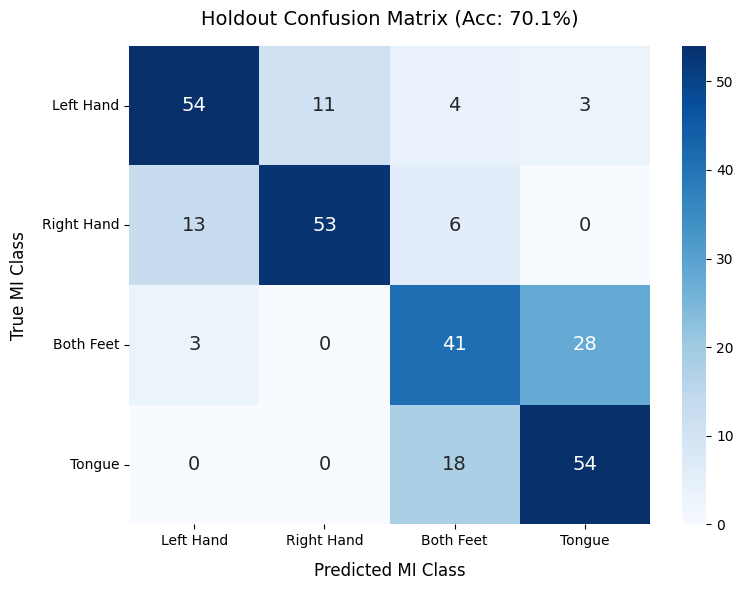

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5341 | Train Acc: 27.36%
Epoch [20/750] | CE Loss: 1.5066 | Train Acc: 27.08%
Epoch [30/750] | CE Loss: 1.4741 | Train Acc: 27.78%
Epoch [40/750] | CE Loss: 1.4467 | Train Acc: 29.51%
Epoch [50/750] | CE Loss: 1.4387 | Train Acc: 29.38%
Epoch [60/750] | CE Loss: 1.3939 | Train Acc: 32.43%
Epoch [70/750] | CE Loss: 1.3520 | Train Acc: 35.83%
Epoch [80/750] | CE Loss: 1.3215 | Train Acc: 39.58%
Epoch [90/750] | CE Loss: 1.2981 | Train Acc: 42.22%
Epoch [100/750] | CE Loss: 1.2667 | Train Acc: 43.33%
Epoch [110/750] | CE Loss: 1.2343 | Train Acc: 45.28%
Epoch [120/750] | CE Loss: 1.2268 | Train Acc: 45.28%
Epoch [130/750] | CE Loss: 1.2235 | Train Acc: 45.42%
Epoch [140/750] | CE Loss: 1.1974 | Train Acc: 47.50%
Epoch [150/750] | CE Loss: 1.1732 | Train Acc: 47.01%
Epoch [160/750] | CE Loss: 1.1646 | Train Acc: 46.88%
Epoch [170/750] | CE Loss: 1.1665 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  68.75%



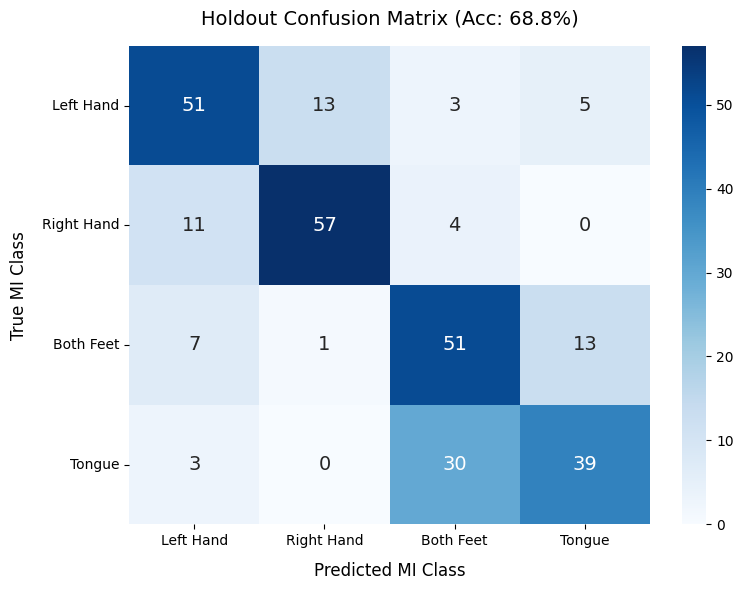

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6266 | Train Acc: 23.75%
Epoch [20/750] | CE Loss: 1.5583 | Train Acc: 25.69%
Epoch [30/750] | CE Loss: 1.5479 | Train Acc: 25.35%
Epoch [40/750] | CE Loss: 1.4936 | Train Acc: 25.97%
Epoch [50/750] | CE Loss: 1.4800 | Train Acc: 24.58%
Epoch [60/750] | CE Loss: 1.4600 | Train Acc: 26.88%
Epoch [70/750] | CE Loss: 1.4385 | Train Acc: 25.49%
Epoch [80/750] | CE Loss: 1.4323 | Train Acc: 26.88%
Epoch [90/750] | CE Loss: 1.4347 | Train Acc: 25.90%
Epoch [100/750] | CE Loss: 1.3941 | Train Acc: 28.06%
Epoch [110/750] | CE Loss: 1.3893 | Train Acc: 29.17%
Epoch [120/750] | CE Loss: 1.3599 | Train Acc: 33.26%
Epoch [130/750] | CE Loss: 1.3129 | Train Acc: 36.67%
Epoch [140/750] | CE Loss: 1.2848 | Train Acc: 39.72%
Epoch [150/750] | CE Loss: 1.2375 | Train Acc: 41.32%
Epoch [160/750] | CE Loss: 1.2064 | Train Acc: 45.21%
Epoch [170/750] | CE Loss: 1.1835 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  64.58%



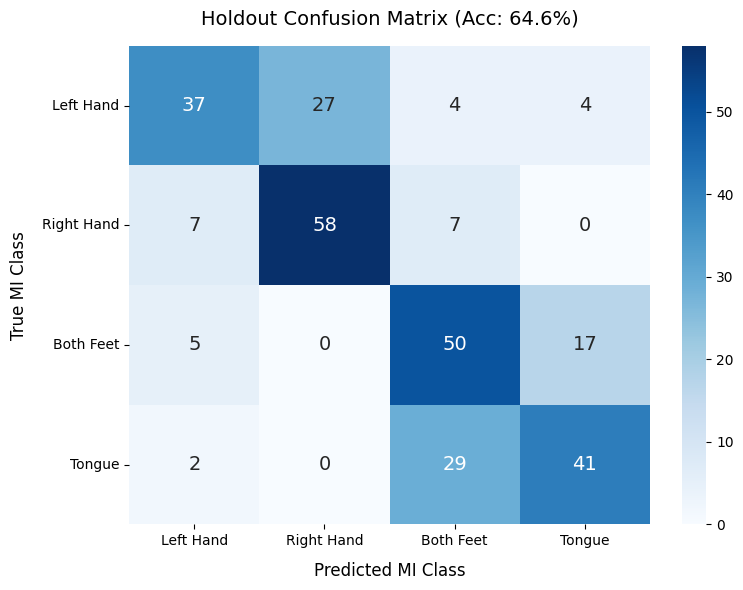

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5942 | Train Acc: 25.21%
Epoch [20/750] | CE Loss: 1.5316 | Train Acc: 23.96%
Epoch [30/750] | CE Loss: 1.5112 | Train Acc: 22.99%
Epoch [40/750] | CE Loss: 1.4862 | Train Acc: 24.86%
Epoch [50/750] | CE Loss: 1.4687 | Train Acc: 23.75%
Epoch [60/750] | CE Loss: 1.4336 | Train Acc: 26.18%
Epoch [70/750] | CE Loss: 1.4290 | Train Acc: 26.88%
Epoch [80/750] | CE Loss: 1.4172 | Train Acc: 28.47%
Epoch [90/750] | CE Loss: 1.3995 | Train Acc: 29.38%
Epoch [100/750] | CE Loss: 1.3849 | Train Acc: 30.35%
Epoch [110/750] | CE Loss: 1.3675 | Train Acc: 32.78%
Epoch [120/750] | CE Loss: 1.3231 | Train Acc: 37.08%
Epoch [130/750] | CE Loss: 1.3102 | Train Acc: 38.96%
Epoch [140/750] | CE Loss: 1.2630 | Train Acc: 40.00%
Epoch [150/750] | CE Loss: 1.2381 | Train Acc: 42.57%
Epoch [160/750] | CE Loss: 1.2280 | Train Acc: 41.46%
Epoch [170/750] | CE Loss: 1.1885 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  63.19%



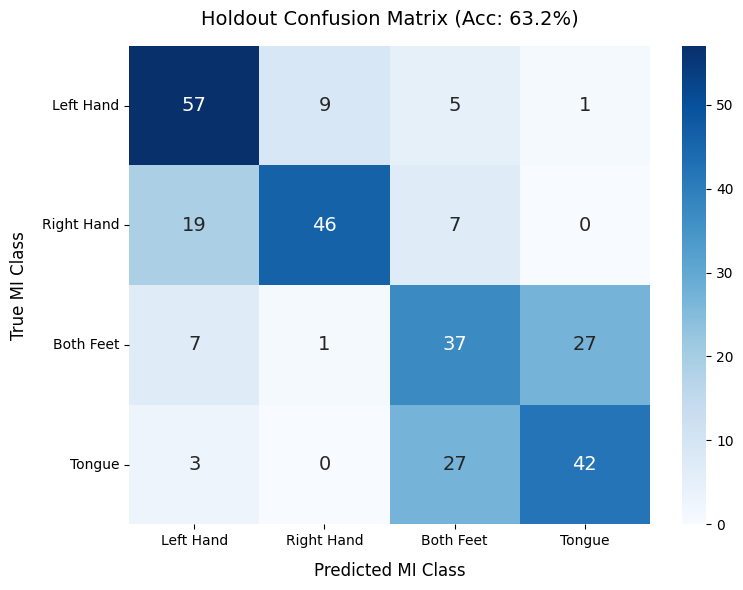

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5609 | Train Acc: 26.88%
Epoch [20/750] | CE Loss: 1.5536 | Train Acc: 23.96%
Epoch [30/750] | CE Loss: 1.5342 | Train Acc: 23.89%
Epoch [40/750] | CE Loss: 1.4933 | Train Acc: 25.97%
Epoch [50/750] | CE Loss: 1.4780 | Train Acc: 28.12%
Epoch [60/750] | CE Loss: 1.4561 | Train Acc: 25.49%
Epoch [70/750] | CE Loss: 1.4106 | Train Acc: 28.96%
Epoch [80/750] | CE Loss: 1.3907 | Train Acc: 30.69%
Epoch [90/750] | CE Loss: 1.3360 | Train Acc: 35.28%
Epoch [100/750] | CE Loss: 1.3191 | Train Acc: 35.83%
Epoch [110/750] | CE Loss: 1.2753 | Train Acc: 38.26%
Epoch [120/750] | CE Loss: 1.2443 | Train Acc: 40.00%
Epoch [130/750] | CE Loss: 1.1992 | Train Acc: 42.71%
Epoch [140/750] | CE Loss: 1.1677 | Train Acc: 45.21%
Epoch [150/750] | CE Loss: 1.1648 | Train Acc: 47.71%
Epoch [160/750] | CE Loss: 1.1539 | Train Acc: 45.56%
Epoch [170/750] | CE Loss: 1.1343 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  57.29%



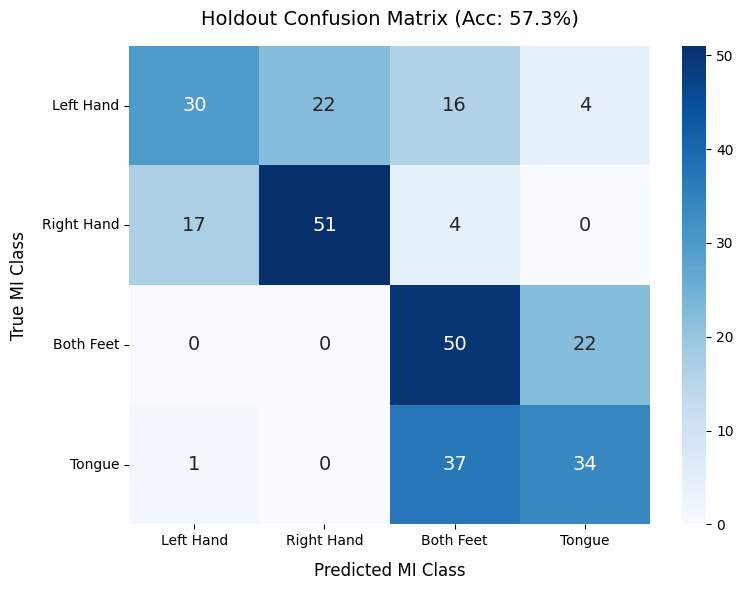

End of 5


In [9]:
lists.append(_run_(1, TCNet, parameters, batch_size, epochs, device, preprocessor))

## Subject 2


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5860 | Train Acc: 24.24%
Epoch [20/750] | CE Loss: 1.5518 | Train Acc: 24.03%
Epoch [30/750] | CE Loss: 1.4992 | Train Acc: 25.49%
Epoch [40/750] | CE Loss: 1.4733 | Train Acc: 26.25%
Epoch [50/750] | CE Loss: 1.4757 | Train Acc: 25.00%
Epoch [60/750] | CE Loss: 1.4493 | Train Acc: 26.74%
Epoch [70/750] | CE Loss: 1.4343 | Train Acc: 24.79%
Epoch [80/750] | CE Loss: 1.4303 | Train Acc: 26.53%
Epoch [90/750] | CE Loss: 1.4258 | Train Acc: 24.79%
Epoch [100/750] | CE Loss: 1.4083 | Train Acc: 26.39%
Epoch [110/750] | CE Loss: 1.4173 | Train Acc: 25.07%
Epoch [120/750] | CE Loss: 1.4225 | Train Acc: 25.28%
Epoch [130/750] | CE Loss: 1.4125 | Train Acc: 24.93%
Epoch [140/750] | CE Loss: 1.4066 | Train Acc: 25.35%
Epoch [150/750] | CE Loss: 1.4058 | Train Acc: 25.14%
Epoch [160/750] | CE Loss: 1.4031 | Train Acc: 26.94%
Epoch [170/750] | CE Loss: 1.3943 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  36.11%



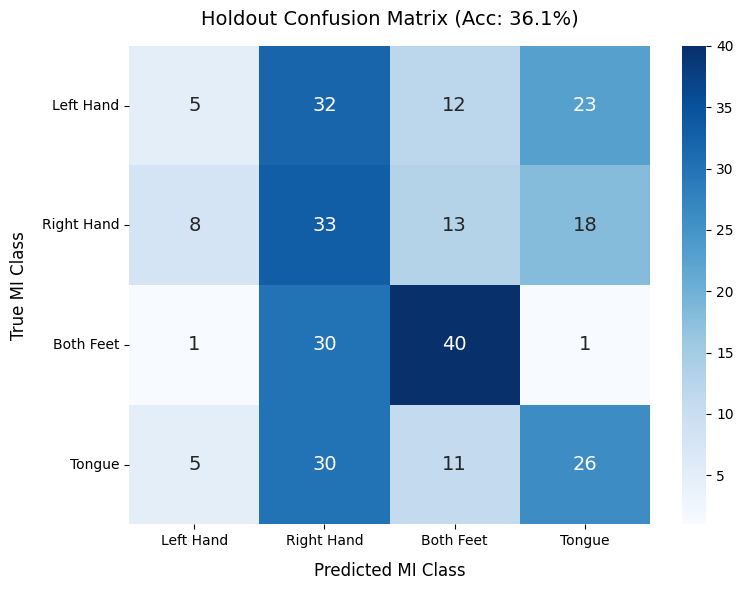

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6054 | Train Acc: 24.72%
Epoch [20/750] | CE Loss: 1.5500 | Train Acc: 26.11%
Epoch [30/750] | CE Loss: 1.5441 | Train Acc: 26.46%
Epoch [40/750] | CE Loss: 1.5099 | Train Acc: 25.76%
Epoch [50/750] | CE Loss: 1.4624 | Train Acc: 26.11%
Epoch [60/750] | CE Loss: 1.4731 | Train Acc: 24.72%
Epoch [70/750] | CE Loss: 1.4623 | Train Acc: 24.79%
Epoch [80/750] | CE Loss: 1.4489 | Train Acc: 26.46%
Epoch [90/750] | CE Loss: 1.4263 | Train Acc: 26.04%
Epoch [100/750] | CE Loss: 1.4224 | Train Acc: 25.07%
Epoch [110/750] | CE Loss: 1.4050 | Train Acc: 27.43%
Epoch [120/750] | CE Loss: 1.4151 | Train Acc: 25.62%
Epoch [130/750] | CE Loss: 1.4038 | Train Acc: 25.90%
Epoch [140/750] | CE Loss: 1.3953 | Train Acc: 27.71%
Epoch [150/750] | CE Loss: 1.3947 | Train Acc: 28.89%
Epoch [160/750] | CE Loss: 1.3921 | Train Acc: 27.50%
Epoch [170/750] | CE Loss: 1.4024 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  41.67%



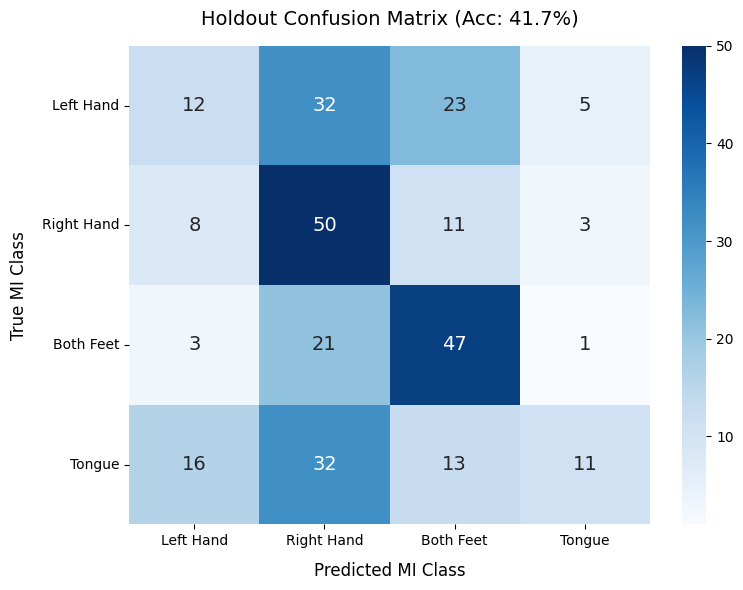

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.7563 | Train Acc: 25.42%
Epoch [20/750] | CE Loss: 1.6165 | Train Acc: 25.90%
Epoch [30/750] | CE Loss: 1.5417 | Train Acc: 25.28%
Epoch [40/750] | CE Loss: 1.4865 | Train Acc: 26.53%
Epoch [50/750] | CE Loss: 1.4831 | Train Acc: 24.31%
Epoch [60/750] | CE Loss: 1.4472 | Train Acc: 25.90%
Epoch [70/750] | CE Loss: 1.4484 | Train Acc: 24.17%
Epoch [80/750] | CE Loss: 1.4299 | Train Acc: 25.83%
Epoch [90/750] | CE Loss: 1.4091 | Train Acc: 27.50%
Epoch [100/750] | CE Loss: 1.4203 | Train Acc: 26.39%
Epoch [110/750] | CE Loss: 1.4214 | Train Acc: 24.38%
Epoch [120/750] | CE Loss: 1.4105 | Train Acc: 26.25%
Epoch [130/750] | CE Loss: 1.3992 | Train Acc: 27.50%
Epoch [140/750] | CE Loss: 1.3861 | Train Acc: 27.85%
Epoch [150/750] | CE Loss: 1.3905 | Train Acc: 27.43%
Epoch [160/750] | CE Loss: 1.3644 | Train Acc: 31.46%
Epoch [170/750] | CE Loss: 1.3709 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  38.19%



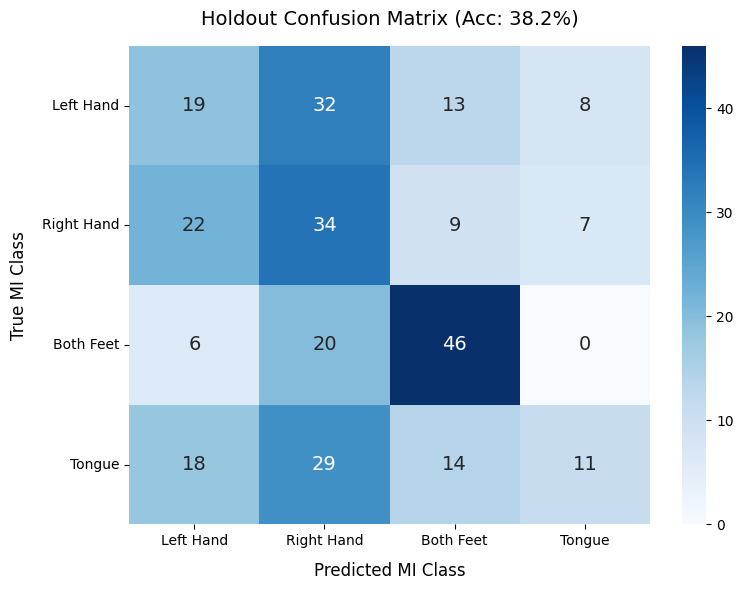

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5750 | Train Acc: 24.86%
Epoch [20/750] | CE Loss: 1.5224 | Train Acc: 25.28%
Epoch [30/750] | CE Loss: 1.5215 | Train Acc: 21.74%
Epoch [40/750] | CE Loss: 1.4937 | Train Acc: 24.03%
Epoch [50/750] | CE Loss: 1.4599 | Train Acc: 25.49%
Epoch [60/750] | CE Loss: 1.4545 | Train Acc: 26.81%
Epoch [70/750] | CE Loss: 1.4517 | Train Acc: 25.83%
Epoch [80/750] | CE Loss: 1.4348 | Train Acc: 27.22%
Epoch [90/750] | CE Loss: 1.4369 | Train Acc: 24.72%
Epoch [100/750] | CE Loss: 1.4252 | Train Acc: 23.75%
Epoch [110/750] | CE Loss: 1.4243 | Train Acc: 25.49%
Epoch [120/750] | CE Loss: 1.4218 | Train Acc: 26.32%
Epoch [130/750] | CE Loss: 1.4116 | Train Acc: 26.18%
Epoch [140/750] | CE Loss: 1.4046 | Train Acc: 26.11%
Epoch [150/750] | CE Loss: 1.3959 | Train Acc: 26.74%
Epoch [160/750] | CE Loss: 1.4010 | Train Acc: 25.97%
Epoch [170/750] | CE Loss: 1.3827 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  35.76%



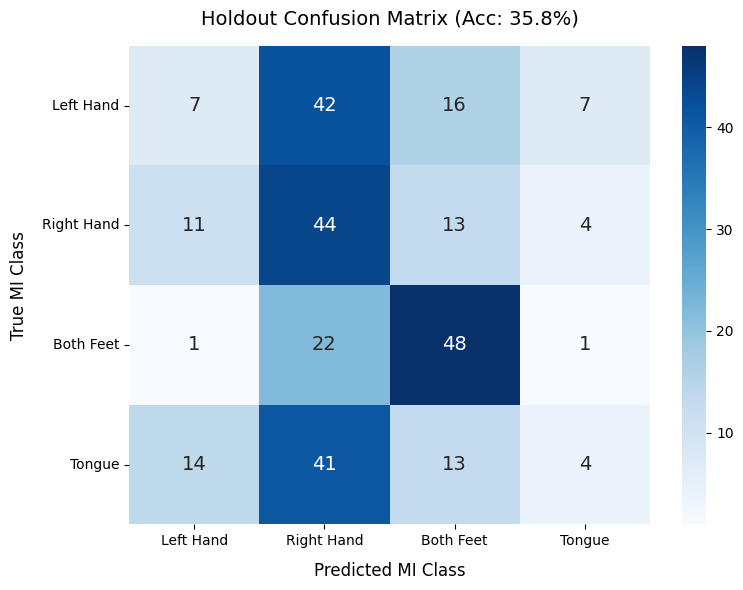

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5819 | Train Acc: 25.49%
Epoch [20/750] | CE Loss: 1.5342 | Train Acc: 26.25%
Epoch [30/750] | CE Loss: 1.5104 | Train Acc: 26.67%
Epoch [40/750] | CE Loss: 1.5070 | Train Acc: 25.28%
Epoch [50/750] | CE Loss: 1.4921 | Train Acc: 25.35%
Epoch [60/750] | CE Loss: 1.4727 | Train Acc: 25.35%
Epoch [70/750] | CE Loss: 1.4432 | Train Acc: 26.74%
Epoch [80/750] | CE Loss: 1.4391 | Train Acc: 25.21%
Epoch [90/750] | CE Loss: 1.4338 | Train Acc: 24.10%
Epoch [100/750] | CE Loss: 1.4283 | Train Acc: 24.86%
Epoch [110/750] | CE Loss: 1.4140 | Train Acc: 27.64%
Epoch [120/750] | CE Loss: 1.4172 | Train Acc: 25.14%
Epoch [130/750] | CE Loss: 1.4098 | Train Acc: 25.83%
Epoch [140/750] | CE Loss: 1.4183 | Train Acc: 25.21%
Epoch [150/750] | CE Loss: 1.4060 | Train Acc: 26.32%
Epoch [160/750] | CE Loss: 1.4039 | Train Acc: 28.89%
Epoch [170/750] | CE Loss: 1.4034 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  44.44%



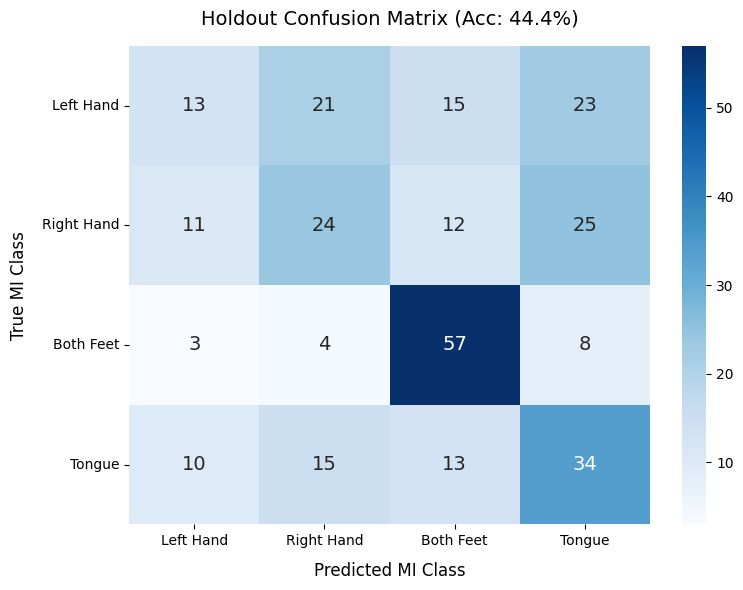

End of 5


In [10]:
lists.append(_run_(2, TCNet, parameters, batch_size, epochs, device, preprocessor))

## Subject 3


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6151 | Train Acc: 25.35%
Epoch [20/750] | CE Loss: 1.5880 | Train Acc: 25.28%
Epoch [30/750] | CE Loss: 1.5051 | Train Acc: 27.71%
Epoch [40/750] | CE Loss: 1.5073 | Train Acc: 25.00%
Epoch [50/750] | CE Loss: 1.4640 | Train Acc: 27.22%
Epoch [60/750] | CE Loss: 1.4564 | Train Acc: 27.29%
Epoch [70/750] | CE Loss: 1.4339 | Train Acc: 27.43%
Epoch [80/750] | CE Loss: 1.4017 | Train Acc: 31.25%
Epoch [90/750] | CE Loss: 1.3914 | Train Acc: 28.68%
Epoch [100/750] | CE Loss: 1.3404 | Train Acc: 35.56%
Epoch [110/750] | CE Loss: 1.3249 | Train Acc: 35.90%
Epoch [120/750] | CE Loss: 1.2893 | Train Acc: 38.61%
Epoch [130/750] | CE Loss: 1.2668 | Train Acc: 40.49%
Epoch [140/750] | CE Loss: 1.2590 | Train Acc: 43.82%
Epoch [150/750] | CE Loss: 1.2370 | Train Acc: 43.06%
Epoch [160/750] | CE Loss: 1.2368 | Train Acc: 44.17%
Epoch [170/750] | CE Loss: 1.2218 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  73.26%



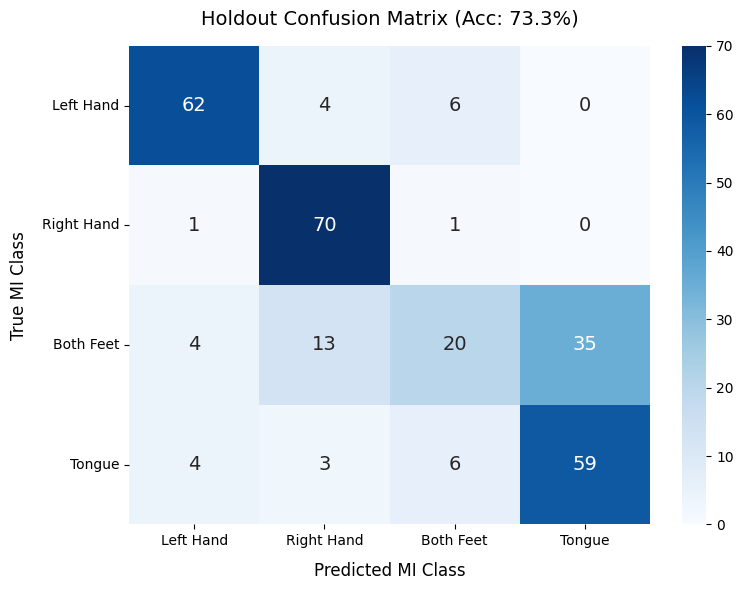

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6505 | Train Acc: 23.61%
Epoch [20/750] | CE Loss: 1.5683 | Train Acc: 23.75%
Epoch [30/750] | CE Loss: 1.5536 | Train Acc: 25.76%
Epoch [40/750] | CE Loss: 1.5011 | Train Acc: 24.86%
Epoch [50/750] | CE Loss: 1.4769 | Train Acc: 25.35%
Epoch [60/750] | CE Loss: 1.4722 | Train Acc: 25.35%
Epoch [70/750] | CE Loss: 1.4297 | Train Acc: 26.81%
Epoch [80/750] | CE Loss: 1.4263 | Train Acc: 27.15%
Epoch [90/750] | CE Loss: 1.4297 | Train Acc: 27.29%
Epoch [100/750] | CE Loss: 1.4037 | Train Acc: 31.04%
Epoch [110/750] | CE Loss: 1.3751 | Train Acc: 31.32%
Epoch [120/750] | CE Loss: 1.3634 | Train Acc: 32.57%
Epoch [130/750] | CE Loss: 1.3301 | Train Acc: 35.90%
Epoch [140/750] | CE Loss: 1.3435 | Train Acc: 36.94%
Epoch [150/750] | CE Loss: 1.3087 | Train Acc: 37.08%
Epoch [160/750] | CE Loss: 1.2880 | Train Acc: 41.67%
Epoch [170/750] | CE Loss: 1.2881 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  73.26%



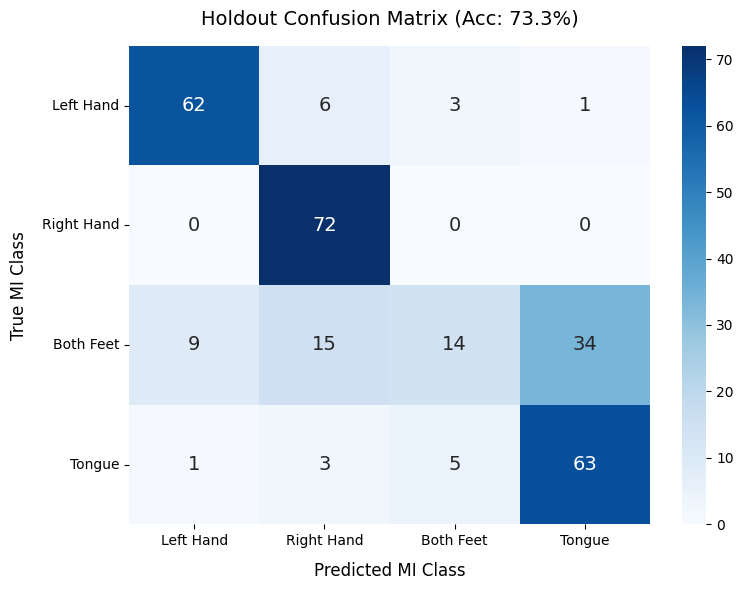

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5526 | Train Acc: 24.58%
Epoch [20/750] | CE Loss: 1.5185 | Train Acc: 25.56%
Epoch [30/750] | CE Loss: 1.4960 | Train Acc: 27.36%
Epoch [40/750] | CE Loss: 1.4752 | Train Acc: 25.49%
Epoch [50/750] | CE Loss: 1.4513 | Train Acc: 25.35%
Epoch [60/750] | CE Loss: 1.4306 | Train Acc: 27.92%
Epoch [70/750] | CE Loss: 1.4386 | Train Acc: 27.50%
Epoch [80/750] | CE Loss: 1.4232 | Train Acc: 25.97%
Epoch [90/750] | CE Loss: 1.4352 | Train Acc: 23.82%
Epoch [100/750] | CE Loss: 1.4108 | Train Acc: 28.26%
Epoch [110/750] | CE Loss: 1.4053 | Train Acc: 28.82%
Epoch [120/750] | CE Loss: 1.4006 | Train Acc: 28.47%
Epoch [130/750] | CE Loss: 1.3903 | Train Acc: 30.28%
Epoch [140/750] | CE Loss: 1.3941 | Train Acc: 28.12%
Epoch [150/750] | CE Loss: 1.3633 | Train Acc: 34.24%
Epoch [160/750] | CE Loss: 1.3560 | Train Acc: 34.93%
Epoch [170/750] | CE Loss: 1.3380 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  75.69%



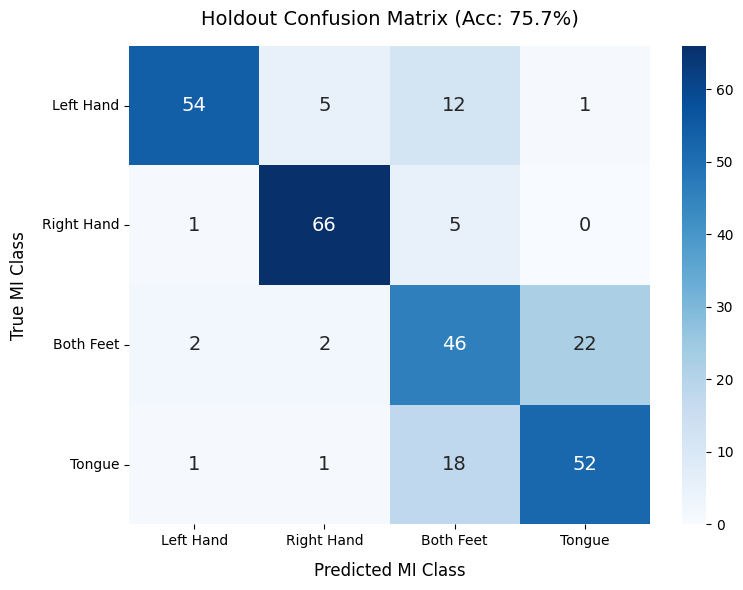

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5740 | Train Acc: 23.75%
Epoch [20/750] | CE Loss: 1.5356 | Train Acc: 24.51%
Epoch [30/750] | CE Loss: 1.4981 | Train Acc: 24.03%
Epoch [40/750] | CE Loss: 1.4734 | Train Acc: 25.28%
Epoch [50/750] | CE Loss: 1.4492 | Train Acc: 27.50%
Epoch [60/750] | CE Loss: 1.4504 | Train Acc: 25.00%
Epoch [70/750] | CE Loss: 1.4254 | Train Acc: 25.56%
Epoch [80/750] | CE Loss: 1.4223 | Train Acc: 26.32%
Epoch [90/750] | CE Loss: 1.4154 | Train Acc: 25.42%
Epoch [100/750] | CE Loss: 1.4203 | Train Acc: 24.17%
Epoch [110/750] | CE Loss: 1.4123 | Train Acc: 25.76%
Epoch [120/750] | CE Loss: 1.4118 | Train Acc: 26.11%
Epoch [130/750] | CE Loss: 1.4024 | Train Acc: 27.29%
Epoch [140/750] | CE Loss: 1.3900 | Train Acc: 27.99%
Epoch [150/750] | CE Loss: 1.3898 | Train Acc: 28.33%
Epoch [160/750] | CE Loss: 1.3906 | Train Acc: 28.06%
Epoch [170/750] | CE Loss: 1.3887 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  72.92%



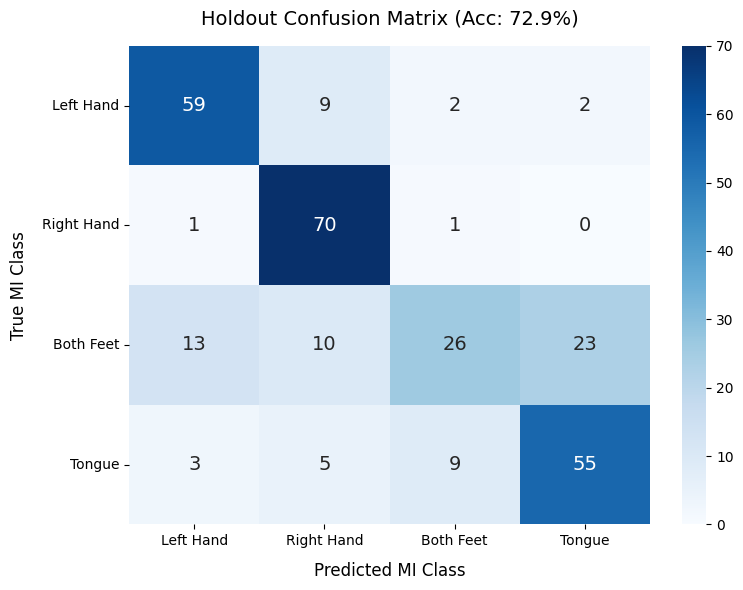

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5685 | Train Acc: 25.49%
Epoch [20/750] | CE Loss: 1.5451 | Train Acc: 25.35%
Epoch [30/750] | CE Loss: 1.5473 | Train Acc: 24.44%
Epoch [40/750] | CE Loss: 1.5098 | Train Acc: 25.35%
Epoch [50/750] | CE Loss: 1.5103 | Train Acc: 24.51%
Epoch [60/750] | CE Loss: 1.4728 | Train Acc: 25.07%
Epoch [70/750] | CE Loss: 1.4571 | Train Acc: 25.35%
Epoch [80/750] | CE Loss: 1.4382 | Train Acc: 24.72%
Epoch [90/750] | CE Loss: 1.4237 | Train Acc: 26.46%
Epoch [100/750] | CE Loss: 1.4006 | Train Acc: 28.82%
Epoch [110/750] | CE Loss: 1.4034 | Train Acc: 28.12%
Epoch [120/750] | CE Loss: 1.4025 | Train Acc: 26.53%
Epoch [130/750] | CE Loss: 1.3838 | Train Acc: 28.68%
Epoch [140/750] | CE Loss: 1.3710 | Train Acc: 30.83%
Epoch [150/750] | CE Loss: 1.3411 | Train Acc: 33.75%
Epoch [160/750] | CE Loss: 1.3367 | Train Acc: 35.62%
Epoch [170/750] | CE Loss: 1.3126 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  72.22%



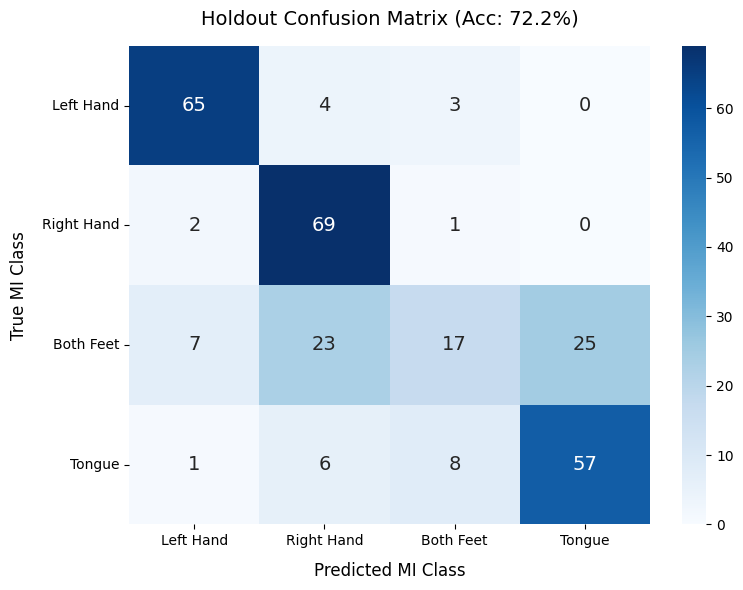

End of 5


In [11]:
lists.append(_run_(3, TCNet, parameters, batch_size, epochs, device, preprocessor))

## Subject 4


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6638 | Train Acc: 25.62%
Epoch [20/750] | CE Loss: 1.6031 | Train Acc: 23.89%
Epoch [30/750] | CE Loss: 1.5840 | Train Acc: 25.97%
Epoch [40/750] | CE Loss: 1.5028 | Train Acc: 26.94%
Epoch [50/750] | CE Loss: 1.5072 | Train Acc: 26.11%
Epoch [60/750] | CE Loss: 1.4896 | Train Acc: 24.79%
Epoch [70/750] | CE Loss: 1.4644 | Train Acc: 26.25%
Epoch [80/750] | CE Loss: 1.4574 | Train Acc: 25.49%
Epoch [90/750] | CE Loss: 1.4312 | Train Acc: 26.81%
Epoch [100/750] | CE Loss: 1.4319 | Train Acc: 25.14%
Epoch [110/750] | CE Loss: 1.4286 | Train Acc: 25.00%
Epoch [120/750] | CE Loss: 1.4263 | Train Acc: 26.53%
Epoch [130/750] | CE Loss: 1.4166 | Train Acc: 26.60%
Epoch [140/750] | CE Loss: 1.4072 | Train Acc: 25.21%
Epoch [150/750] | CE Loss: 1.4086 | Train Acc: 29.17%
Epoch [160/750] | CE Loss: 1.4160 | Train Acc: 26.67%
Epoch [170/750] | CE Loss: 1.3905 | Train Acc: 28.06%

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  36.81%



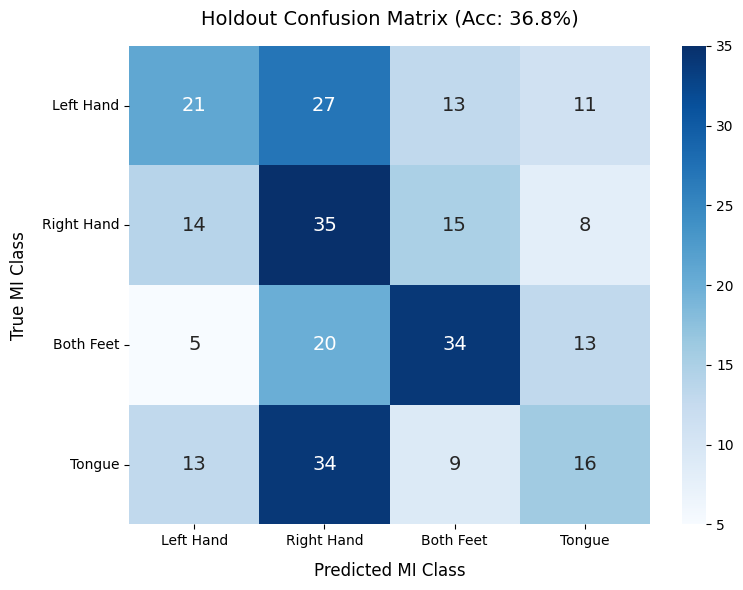

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5841 | Train Acc: 25.83%
Epoch [20/750] | CE Loss: 1.5867 | Train Acc: 23.19%
Epoch [30/750] | CE Loss: 1.5256 | Train Acc: 25.62%
Epoch [40/750] | CE Loss: 1.5062 | Train Acc: 23.75%
Epoch [50/750] | CE Loss: 1.4613 | Train Acc: 28.26%
Epoch [60/750] | CE Loss: 1.4436 | Train Acc: 25.21%
Epoch [70/750] | CE Loss: 1.4627 | Train Acc: 23.75%
Epoch [80/750] | CE Loss: 1.4373 | Train Acc: 24.51%
Epoch [90/750] | CE Loss: 1.4124 | Train Acc: 26.46%
Epoch [100/750] | CE Loss: 1.4100 | Train Acc: 27.22%
Epoch [110/750] | CE Loss: 1.4196 | Train Acc: 24.58%
Epoch [120/750] | CE Loss: 1.4060 | Train Acc: 27.57%
Epoch [130/750] | CE Loss: 1.3964 | Train Acc: 28.40%
Epoch [140/750] | CE Loss: 1.3966 | Train Acc: 25.00%
Epoch [150/750] | CE Loss: 1.3996 | Train Acc: 25.49%
Epoch [160/750] | CE Loss: 1.3927 | Train Acc: 26.25%
Epoch [170/750] | CE Loss: 1.4007 | Train Acc: 25.42%

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  45.49%



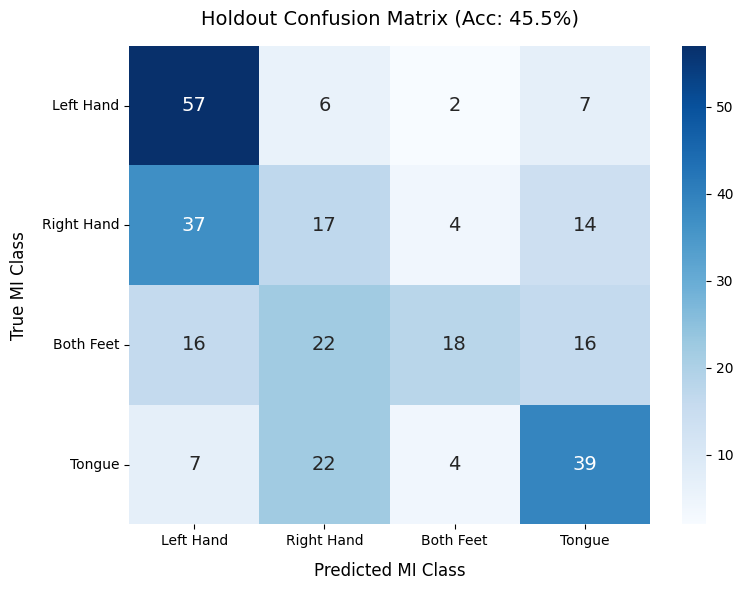

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6423 | Train Acc: 25.07%
Epoch [20/750] | CE Loss: 1.5930 | Train Acc: 24.03%
Epoch [30/750] | CE Loss: 1.5885 | Train Acc: 25.14%
Epoch [40/750] | CE Loss: 1.5304 | Train Acc: 26.88%
Epoch [50/750] | CE Loss: 1.5139 | Train Acc: 25.07%
Epoch [60/750] | CE Loss: 1.4849 | Train Acc: 25.69%
Epoch [70/750] | CE Loss: 1.4638 | Train Acc: 25.90%
Epoch [80/750] | CE Loss: 1.4455 | Train Acc: 26.39%
Epoch [90/750] | CE Loss: 1.4356 | Train Acc: 26.18%
Epoch [100/750] | CE Loss: 1.4292 | Train Acc: 26.81%
Epoch [110/750] | CE Loss: 1.4307 | Train Acc: 25.97%
Epoch [120/750] | CE Loss: 1.4214 | Train Acc: 24.03%
Epoch [130/750] | CE Loss: 1.4258 | Train Acc: 23.89%
Epoch [140/750] | CE Loss: 1.4103 | Train Acc: 24.72%
Epoch [150/750] | CE Loss: 1.4040 | Train Acc: 27.08%
Epoch [160/750] | CE Loss: 1.4098 | Train Acc: 24.38%
Epoch [170/750] | CE Loss: 1.4032 | Train Acc: 25.07%

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  41.32%



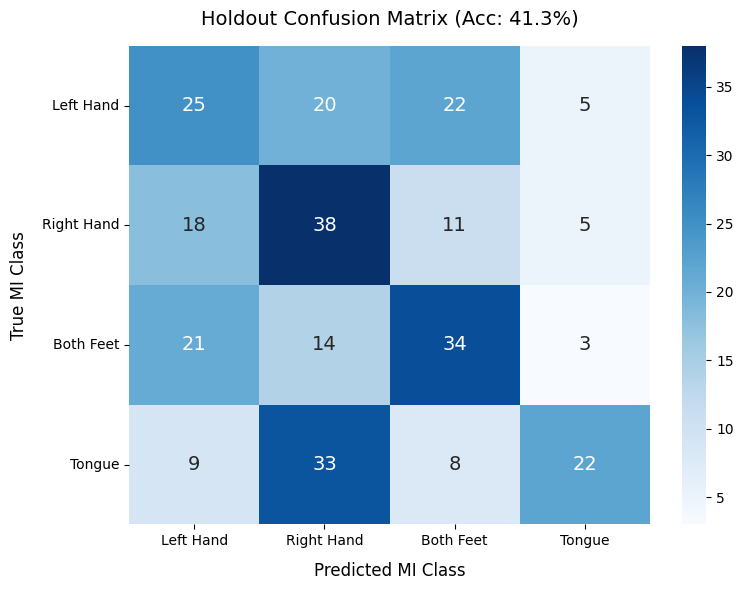

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6324 | Train Acc: 24.65%
Epoch [20/750] | CE Loss: 1.6179 | Train Acc: 23.89%
Epoch [30/750] | CE Loss: 1.5632 | Train Acc: 24.17%
Epoch [40/750] | CE Loss: 1.5040 | Train Acc: 25.83%
Epoch [50/750] | CE Loss: 1.4856 | Train Acc: 24.93%
Epoch [60/750] | CE Loss: 1.4684 | Train Acc: 26.60%
Epoch [70/750] | CE Loss: 1.4715 | Train Acc: 25.28%
Epoch [80/750] | CE Loss: 1.4585 | Train Acc: 23.61%
Epoch [90/750] | CE Loss: 1.4433 | Train Acc: 25.83%
Epoch [100/750] | CE Loss: 1.4472 | Train Acc: 24.03%
Epoch [110/750] | CE Loss: 1.4224 | Train Acc: 26.46%
Epoch [120/750] | CE Loss: 1.4454 | Train Acc: 22.50%
Epoch [130/750] | CE Loss: 1.4195 | Train Acc: 27.01%
Epoch [140/750] | CE Loss: 1.4286 | Train Acc: 25.00%
Epoch [150/750] | CE Loss: 1.4453 | Train Acc: 23.33%
Epoch [160/750] | CE Loss: 1.4207 | Train Acc: 25.42%
Epoch [170/750] | CE Loss: 1.4146 | Train Acc: 25.97%

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  37.15%



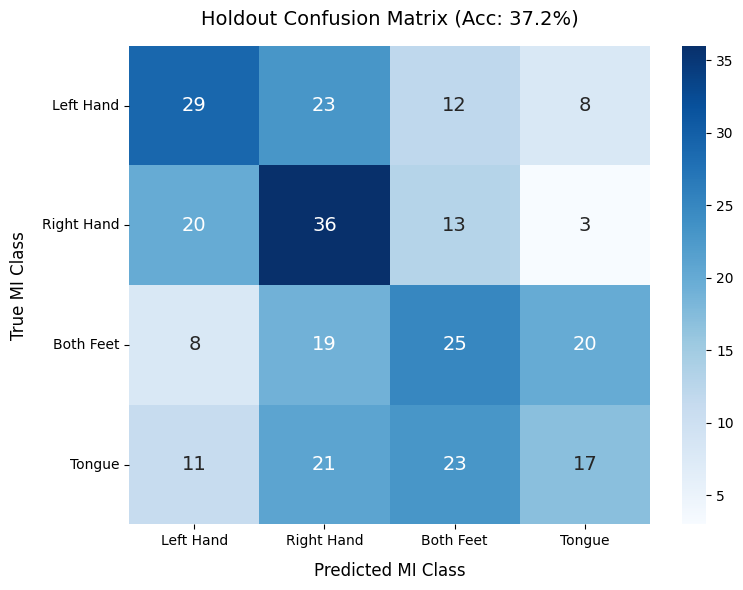

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6618 | Train Acc: 23.12%
Epoch [20/750] | CE Loss: 1.6113 | Train Acc: 23.68%
Epoch [30/750] | CE Loss: 1.5527 | Train Acc: 24.10%
Epoch [40/750] | CE Loss: 1.5071 | Train Acc: 27.43%
Epoch [50/750] | CE Loss: 1.4826 | Train Acc: 27.85%
Epoch [60/750] | CE Loss: 1.4778 | Train Acc: 25.21%
Epoch [70/750] | CE Loss: 1.4696 | Train Acc: 25.21%
Epoch [80/750] | CE Loss: 1.4606 | Train Acc: 24.79%
Epoch [90/750] | CE Loss: 1.4660 | Train Acc: 24.38%
Epoch [100/750] | CE Loss: 1.4501 | Train Acc: 24.03%
Epoch [110/750] | CE Loss: 1.4331 | Train Acc: 26.46%
Epoch [120/750] | CE Loss: 1.4185 | Train Acc: 27.50%
Epoch [130/750] | CE Loss: 1.4146 | Train Acc: 27.57%
Epoch [140/750] | CE Loss: 1.4072 | Train Acc: 25.90%
Epoch [150/750] | CE Loss: 1.4078 | Train Acc: 25.97%
Epoch [160/750] | CE Loss: 1.4083 | Train Acc: 26.81%
Epoch [170/750] | CE Loss: 1.4154 | Train Acc: 25.76%

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  41.67%



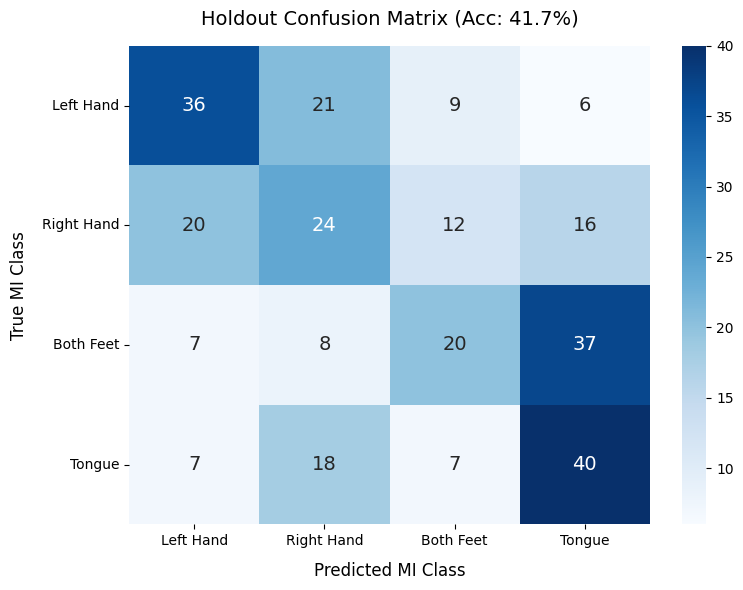

End of 5


In [12]:
lists.append(_run_(4, TCNet, parameters, batch_size, epochs, device, preprocessor))

## Subject 5


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6189 | Train Acc: 24.51%
Epoch [20/750] | CE Loss: 1.5687 | Train Acc: 22.92%
Epoch [30/750] | CE Loss: 1.4772 | Train Acc: 26.18%
Epoch [40/750] | CE Loss: 1.4648 | Train Acc: 24.93%
Epoch [50/750] | CE Loss: 1.4487 | Train Acc: 25.14%
Epoch [60/750] | CE Loss: 1.4258 | Train Acc: 25.69%
Epoch [70/750] | CE Loss: 1.4271 | Train Acc: 25.56%
Epoch [80/750] | CE Loss: 1.4157 | Train Acc: 26.04%
Epoch [90/750] | CE Loss: 1.4147 | Train Acc: 25.56%
Epoch [100/750] | CE Loss: 1.4178 | Train Acc: 24.10%
Epoch [110/750] | CE Loss: 1.4031 | Train Acc: 25.00%
Epoch [120/750] | CE Loss: 1.4111 | Train Acc: 24.31%
Epoch [130/750] | CE Loss: 1.3955 | Train Acc: 26.53%
Epoch [140/750] | CE Loss: 1.3968 | Train Acc: 25.69%
Epoch [150/750] | CE Loss: 1.3968 | Train Acc: 25.62%
Epoch [160/750] | CE Loss: 1.3953 | Train Acc: 26.53%
Epoch [170/750] | CE Loss: 1.3970 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  31.94%



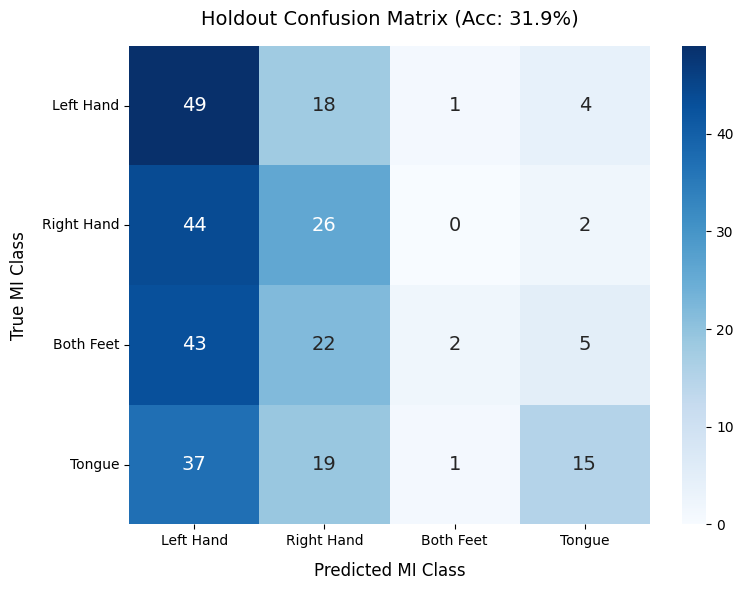

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6667 | Train Acc: 24.17%
Epoch [20/750] | CE Loss: 1.5765 | Train Acc: 24.58%
Epoch [30/750] | CE Loss: 1.5517 | Train Acc: 25.49%
Epoch [40/750] | CE Loss: 1.5145 | Train Acc: 24.17%
Epoch [50/750] | CE Loss: 1.4969 | Train Acc: 24.38%
Epoch [60/750] | CE Loss: 1.4558 | Train Acc: 26.81%
Epoch [70/750] | CE Loss: 1.4549 | Train Acc: 25.62%
Epoch [80/750] | CE Loss: 1.4357 | Train Acc: 23.47%
Epoch [90/750] | CE Loss: 1.4302 | Train Acc: 24.86%
Epoch [100/750] | CE Loss: 1.4301 | Train Acc: 23.54%
Epoch [110/750] | CE Loss: 1.4241 | Train Acc: 24.65%
Epoch [120/750] | CE Loss: 1.4099 | Train Acc: 23.54%
Epoch [130/750] | CE Loss: 1.4028 | Train Acc: 26.18%
Epoch [140/750] | CE Loss: 1.4027 | Train Acc: 25.21%
Epoch [150/750] | CE Loss: 1.4010 | Train Acc: 25.14%
Epoch [160/750] | CE Loss: 1.3991 | Train Acc: 24.65%
Epoch [170/750] | CE Loss: 1.4065 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  31.60%



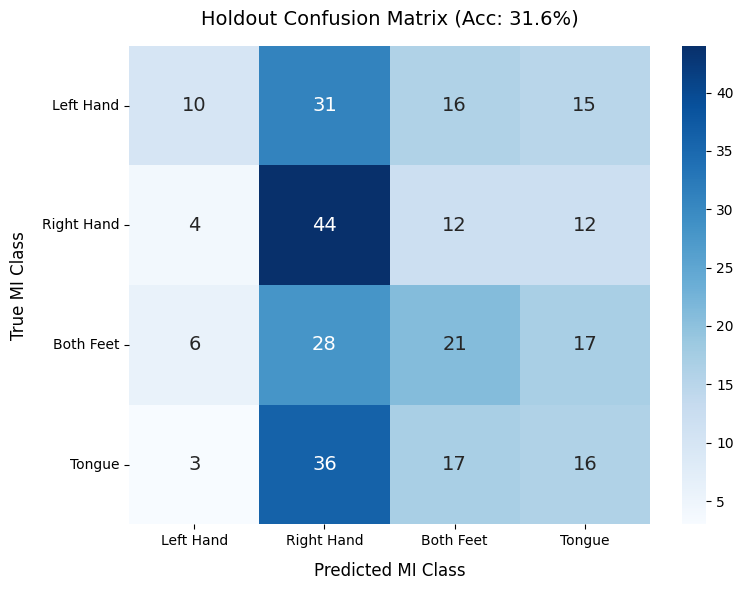

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6015 | Train Acc: 25.49%
Epoch [20/750] | CE Loss: 1.5390 | Train Acc: 25.35%
Epoch [30/750] | CE Loss: 1.5390 | Train Acc: 23.33%
Epoch [40/750] | CE Loss: 1.5126 | Train Acc: 23.33%
Epoch [50/750] | CE Loss: 1.4897 | Train Acc: 26.32%
Epoch [60/750] | CE Loss: 1.4551 | Train Acc: 24.38%
Epoch [70/750] | CE Loss: 1.4365 | Train Acc: 26.46%
Epoch [80/750] | CE Loss: 1.4429 | Train Acc: 25.07%
Epoch [90/750] | CE Loss: 1.4316 | Train Acc: 24.03%
Epoch [100/750] | CE Loss: 1.4247 | Train Acc: 25.69%
Epoch [110/750] | CE Loss: 1.4184 | Train Acc: 27.57%
Epoch [120/750] | CE Loss: 1.4170 | Train Acc: 25.49%
Epoch [130/750] | CE Loss: 1.4029 | Train Acc: 26.81%
Epoch [140/750] | CE Loss: 1.3987 | Train Acc: 26.25%
Epoch [150/750] | CE Loss: 1.4071 | Train Acc: 27.78%
Epoch [160/750] | CE Loss: 1.4059 | Train Acc: 24.51%
Epoch [170/750] | CE Loss: 1.3963 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  34.72%



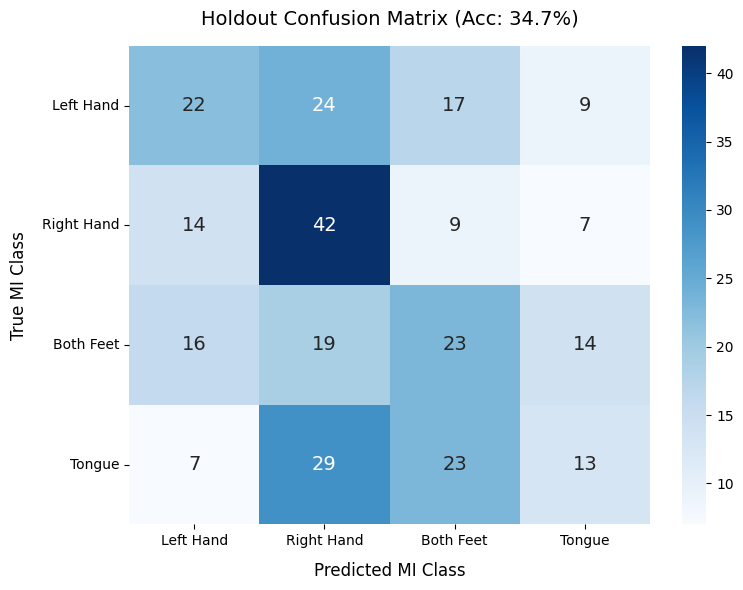

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6326 | Train Acc: 27.92%
Epoch [20/750] | CE Loss: 1.5933 | Train Acc: 26.11%
Epoch [30/750] | CE Loss: 1.5207 | Train Acc: 25.76%
Epoch [40/750] | CE Loss: 1.5268 | Train Acc: 26.53%
Epoch [50/750] | CE Loss: 1.5033 | Train Acc: 25.07%
Epoch [60/750] | CE Loss: 1.4723 | Train Acc: 25.42%
Epoch [70/750] | CE Loss: 1.4445 | Train Acc: 27.08%
Epoch [80/750] | CE Loss: 1.4511 | Train Acc: 26.46%
Epoch [90/750] | CE Loss: 1.4448 | Train Acc: 24.79%
Epoch [100/750] | CE Loss: 1.4357 | Train Acc: 25.69%
Epoch [110/750] | CE Loss: 1.4311 | Train Acc: 26.60%
Epoch [120/750] | CE Loss: 1.4214 | Train Acc: 25.76%
Epoch [130/750] | CE Loss: 1.4223 | Train Acc: 25.21%
Epoch [140/750] | CE Loss: 1.4189 | Train Acc: 24.31%
Epoch [150/750] | CE Loss: 1.4039 | Train Acc: 26.67%
Epoch [160/750] | CE Loss: 1.4113 | Train Acc: 25.49%
Epoch [170/750] | CE Loss: 1.4004 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  28.47%



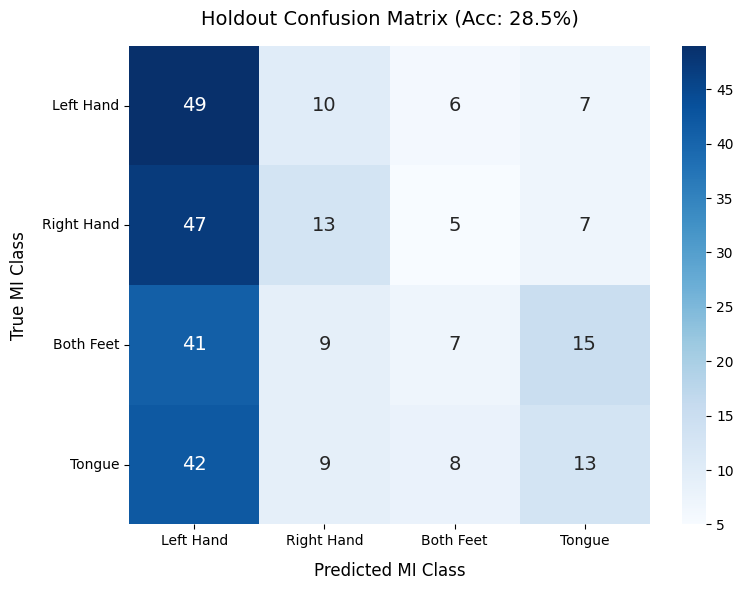

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6128 | Train Acc: 25.21%
Epoch [20/750] | CE Loss: 1.5497 | Train Acc: 27.22%
Epoch [30/750] | CE Loss: 1.5703 | Train Acc: 23.68%
Epoch [40/750] | CE Loss: 1.5135 | Train Acc: 25.00%
Epoch [50/750] | CE Loss: 1.4823 | Train Acc: 26.04%
Epoch [60/750] | CE Loss: 1.4897 | Train Acc: 24.72%
Epoch [70/750] | CE Loss: 1.4661 | Train Acc: 25.97%
Epoch [80/750] | CE Loss: 1.4594 | Train Acc: 24.65%
Epoch [90/750] | CE Loss: 1.4520 | Train Acc: 25.76%
Epoch [100/750] | CE Loss: 1.4372 | Train Acc: 23.54%
Epoch [110/750] | CE Loss: 1.4275 | Train Acc: 26.67%
Epoch [120/750] | CE Loss: 1.4168 | Train Acc: 25.28%
Epoch [130/750] | CE Loss: 1.4135 | Train Acc: 25.42%
Epoch [140/750] | CE Loss: 1.4047 | Train Acc: 28.19%
Epoch [150/750] | CE Loss: 1.4124 | Train Acc: 23.89%
Epoch [160/750] | CE Loss: 1.3981 | Train Acc: 26.88%
Epoch [170/750] | CE Loss: 1.3964 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  42.01%



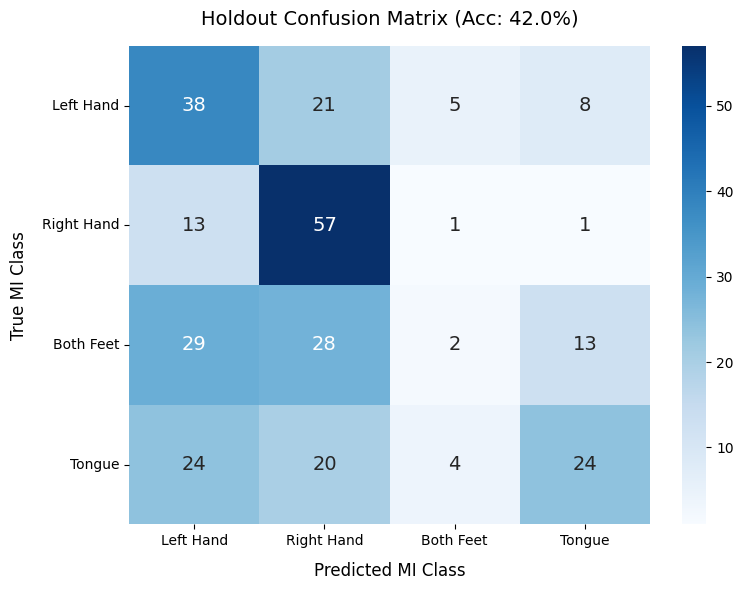

End of 5


In [13]:
lists.append(_run_(5, TCNet, parameters, batch_size, epochs, device, preprocessor))

## Subject 6


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6909 | Train Acc: 24.86%
Epoch [20/750] | CE Loss: 1.6056 | Train Acc: 23.96%
Epoch [30/750] | CE Loss: 1.5695 | Train Acc: 23.26%
Epoch [40/750] | CE Loss: 1.5449 | Train Acc: 25.69%
Epoch [50/750] | CE Loss: 1.4964 | Train Acc: 24.38%
Epoch [60/750] | CE Loss: 1.4746 | Train Acc: 24.03%
Epoch [70/750] | CE Loss: 1.4437 | Train Acc: 26.53%
Epoch [80/750] | CE Loss: 1.4637 | Train Acc: 22.50%
Epoch [90/750] | CE Loss: 1.4266 | Train Acc: 25.69%
Epoch [100/750] | CE Loss: 1.4131 | Train Acc: 26.94%
Epoch [110/750] | CE Loss: 1.4248 | Train Acc: 23.06%
Epoch [120/750] | CE Loss: 1.4101 | Train Acc: 25.28%
Epoch [130/750] | CE Loss: 1.4122 | Train Acc: 24.93%
Epoch [140/750] | CE Loss: 1.4003 | Train Acc: 25.49%
Epoch [150/750] | CE Loss: 1.4037 | Train Acc: 24.86%
Epoch [160/750] | CE Loss: 1.3917 | Train Acc: 27.43%
Epoch [170/750] | CE Loss: 1.3983 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  34.03%



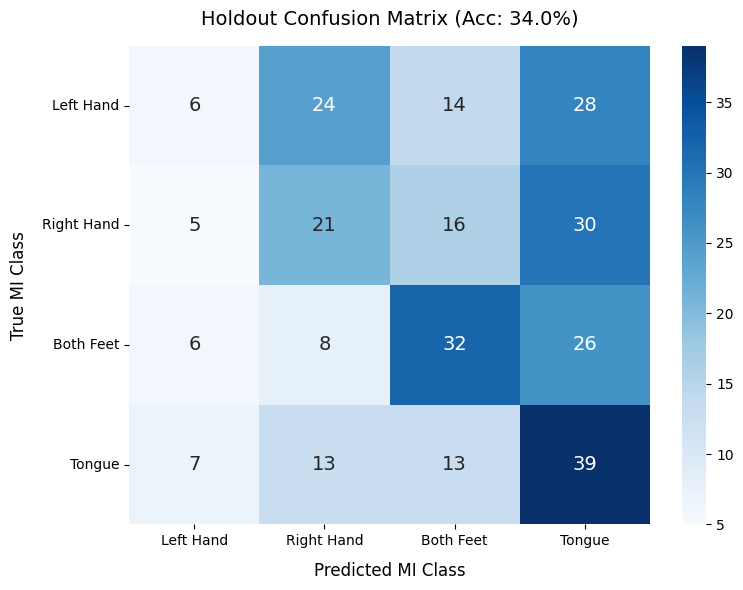

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6006 | Train Acc: 27.08%
Epoch [20/750] | CE Loss: 1.6027 | Train Acc: 23.89%
Epoch [30/750] | CE Loss: 1.5582 | Train Acc: 23.82%
Epoch [40/750] | CE Loss: 1.5349 | Train Acc: 25.21%
Epoch [50/750] | CE Loss: 1.5041 | Train Acc: 24.58%
Epoch [60/750] | CE Loss: 1.5007 | Train Acc: 24.17%
Epoch [70/750] | CE Loss: 1.4538 | Train Acc: 26.25%
Epoch [80/750] | CE Loss: 1.4631 | Train Acc: 23.12%
Epoch [90/750] | CE Loss: 1.4517 | Train Acc: 25.35%
Epoch [100/750] | CE Loss: 1.4337 | Train Acc: 24.79%
Epoch [110/750] | CE Loss: 1.4388 | Train Acc: 26.60%
Epoch [120/750] | CE Loss: 1.4232 | Train Acc: 24.79%
Epoch [130/750] | CE Loss: 1.4223 | Train Acc: 25.69%
Epoch [140/750] | CE Loss: 1.4120 | Train Acc: 25.90%
Epoch [150/750] | CE Loss: 1.4007 | Train Acc: 26.11%
Epoch [160/750] | CE Loss: 1.3976 | Train Acc: 27.15%
Epoch [170/750] | CE Loss: 1.4076 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  32.99%



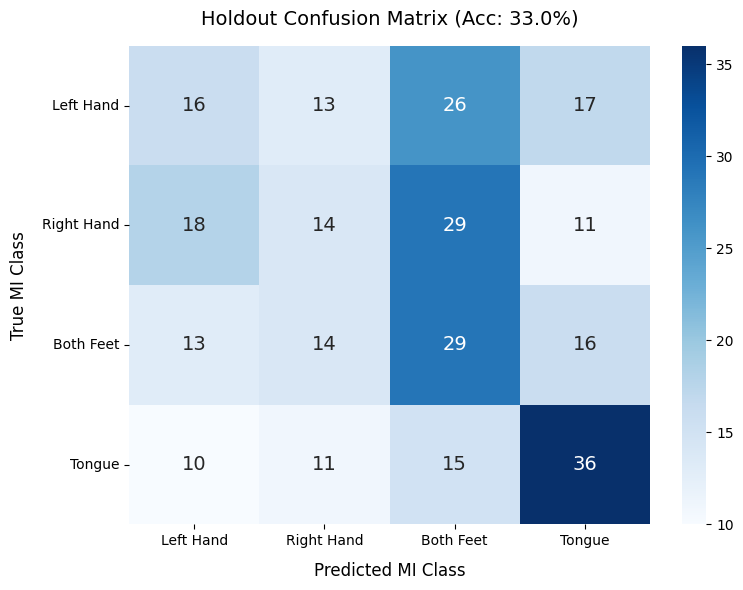

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6128 | Train Acc: 23.82%
Epoch [20/750] | CE Loss: 1.5243 | Train Acc: 27.71%
Epoch [30/750] | CE Loss: 1.5083 | Train Acc: 25.62%
Epoch [40/750] | CE Loss: 1.4686 | Train Acc: 24.17%
Epoch [50/750] | CE Loss: 1.4502 | Train Acc: 27.22%
Epoch [60/750] | CE Loss: 1.4504 | Train Acc: 25.28%
Epoch [70/750] | CE Loss: 1.4282 | Train Acc: 25.90%
Epoch [80/750] | CE Loss: 1.4288 | Train Acc: 25.56%
Epoch [90/750] | CE Loss: 1.4162 | Train Acc: 26.04%
Epoch [100/750] | CE Loss: 1.4146 | Train Acc: 26.11%
Epoch [110/750] | CE Loss: 1.4143 | Train Acc: 25.83%
Epoch [120/750] | CE Loss: 1.4158 | Train Acc: 25.14%
Epoch [130/750] | CE Loss: 1.4068 | Train Acc: 25.69%
Epoch [140/750] | CE Loss: 1.4001 | Train Acc: 26.81%
Epoch [150/750] | CE Loss: 1.4057 | Train Acc: 24.72%
Epoch [160/750] | CE Loss: 1.3982 | Train Acc: 27.29%
Epoch [170/750] | CE Loss: 1.3949 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  31.94%



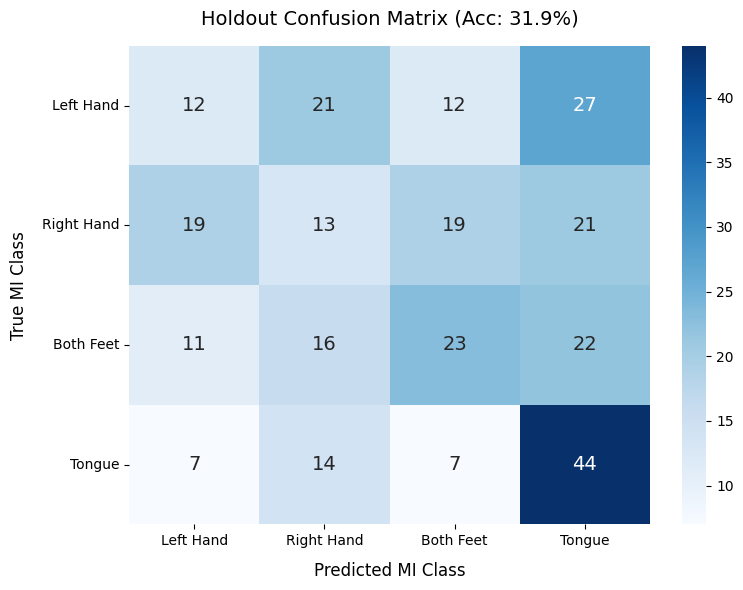

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6029 | Train Acc: 23.12%
Epoch [20/750] | CE Loss: 1.5757 | Train Acc: 26.74%
Epoch [30/750] | CE Loss: 1.5630 | Train Acc: 24.03%
Epoch [40/750] | CE Loss: 1.5432 | Train Acc: 25.14%
Epoch [50/750] | CE Loss: 1.5401 | Train Acc: 23.40%
Epoch [60/750] | CE Loss: 1.4914 | Train Acc: 25.90%
Epoch [70/750] | CE Loss: 1.4662 | Train Acc: 27.01%
Epoch [80/750] | CE Loss: 1.4445 | Train Acc: 25.90%
Epoch [90/750] | CE Loss: 1.4414 | Train Acc: 23.82%
Epoch [100/750] | CE Loss: 1.4651 | Train Acc: 22.99%
Epoch [110/750] | CE Loss: 1.4297 | Train Acc: 25.49%
Epoch [120/750] | CE Loss: 1.4195 | Train Acc: 24.93%
Epoch [130/750] | CE Loss: 1.4216 | Train Acc: 23.33%
Epoch [140/750] | CE Loss: 1.4062 | Train Acc: 27.57%
Epoch [150/750] | CE Loss: 1.4181 | Train Acc: 25.28%
Epoch [160/750] | CE Loss: 1.4104 | Train Acc: 24.51%
Epoch [170/750] | CE Loss: 1.4084 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  29.17%



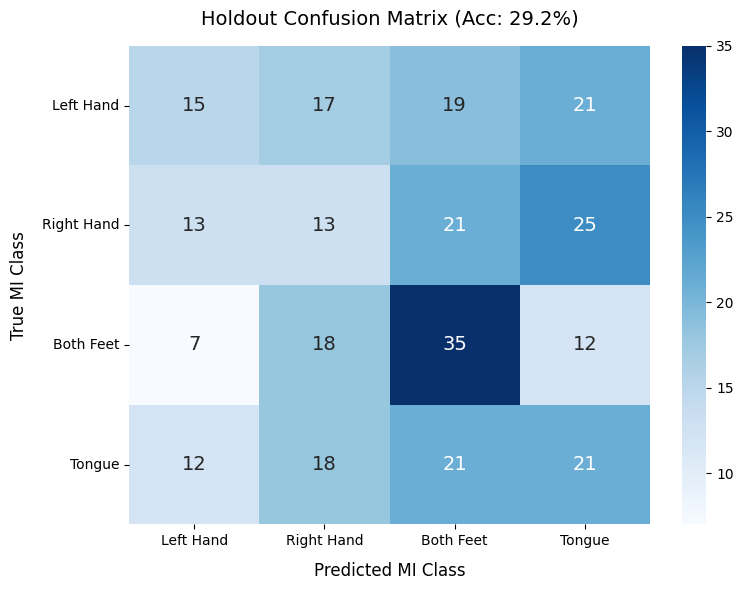

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5402 | Train Acc: 24.58%
Epoch [20/750] | CE Loss: 1.5231 | Train Acc: 24.38%
Epoch [30/750] | CE Loss: 1.4686 | Train Acc: 27.29%
Epoch [40/750] | CE Loss: 1.4719 | Train Acc: 23.89%
Epoch [50/750] | CE Loss: 1.4576 | Train Acc: 25.14%
Epoch [60/750] | CE Loss: 1.4506 | Train Acc: 26.04%
Epoch [70/750] | CE Loss: 1.4303 | Train Acc: 27.92%
Epoch [80/750] | CE Loss: 1.4317 | Train Acc: 25.28%
Epoch [90/750] | CE Loss: 1.4162 | Train Acc: 26.60%
Epoch [100/750] | CE Loss: 1.4221 | Train Acc: 25.00%
Epoch [110/750] | CE Loss: 1.4017 | Train Acc: 27.50%
Epoch [120/750] | CE Loss: 1.4154 | Train Acc: 23.33%
Epoch [130/750] | CE Loss: 1.3996 | Train Acc: 25.21%
Epoch [140/750] | CE Loss: 1.4038 | Train Acc: 26.88%
Epoch [150/750] | CE Loss: 1.4073 | Train Acc: 24.44%
Epoch [160/750] | CE Loss: 1.3957 | Train Acc: 25.49%
Epoch [170/750] | CE Loss: 1.3951 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  29.51%



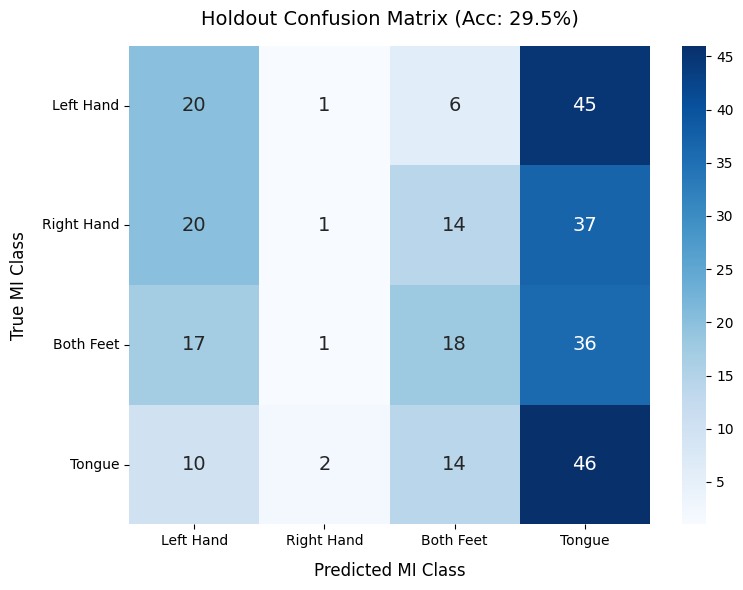

End of 5


In [14]:
lists.append(_run_(6, TCNet, parameters, batch_size, epochs, device, preprocessor))

## Subject 7


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6531 | Train Acc: 26.46%
Epoch [20/750] | CE Loss: 1.5699 | Train Acc: 26.39%
Epoch [30/750] | CE Loss: 1.5466 | Train Acc: 25.76%
Epoch [40/750] | CE Loss: 1.5060 | Train Acc: 25.28%
Epoch [50/750] | CE Loss: 1.5350 | Train Acc: 25.07%
Epoch [60/750] | CE Loss: 1.4993 | Train Acc: 24.44%
Epoch [70/750] | CE Loss: 1.4660 | Train Acc: 26.53%
Epoch [80/750] | CE Loss: 1.4622 | Train Acc: 26.25%
Epoch [90/750] | CE Loss: 1.4646 | Train Acc: 25.90%
Epoch [100/750] | CE Loss: 1.4436 | Train Acc: 24.93%
Epoch [110/750] | CE Loss: 1.4243 | Train Acc: 27.22%
Epoch [120/750] | CE Loss: 1.4284 | Train Acc: 25.00%
Epoch [130/750] | CE Loss: 1.4236 | Train Acc: 25.69%
Epoch [140/750] | CE Loss: 1.4109 | Train Acc: 27.36%
Epoch [150/750] | CE Loss: 1.4064 | Train Acc: 27.78%
Epoch [160/750] | CE Loss: 1.4040 | Train Acc: 30.07%
Epoch [170/750] | CE Loss: 1.4046 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  55.56%



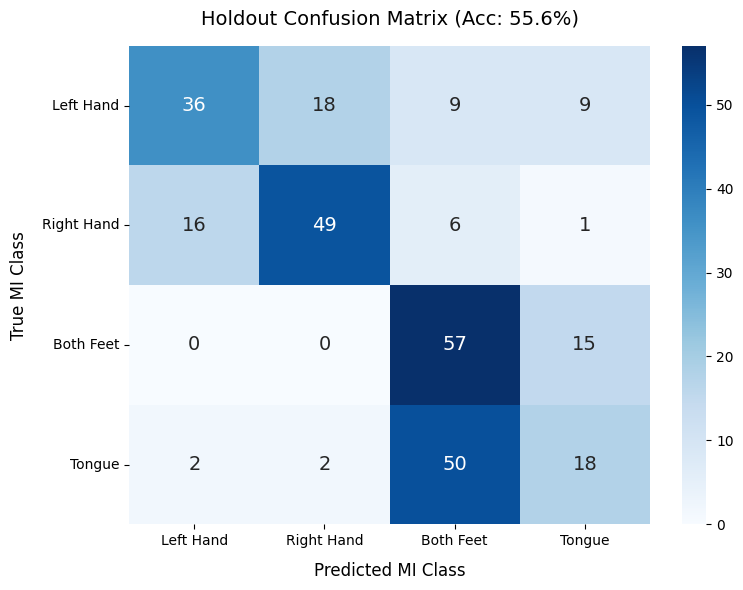

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6001 | Train Acc: 24.93%
Epoch [20/750] | CE Loss: 1.5641 | Train Acc: 27.15%
Epoch [30/750] | CE Loss: 1.5334 | Train Acc: 26.25%
Epoch [40/750] | CE Loss: 1.5109 | Train Acc: 25.76%
Epoch [50/750] | CE Loss: 1.4922 | Train Acc: 24.10%
Epoch [60/750] | CE Loss: 1.4692 | Train Acc: 25.49%
Epoch [70/750] | CE Loss: 1.4737 | Train Acc: 25.56%
Epoch [80/750] | CE Loss: 1.4531 | Train Acc: 25.14%
Epoch [90/750] | CE Loss: 1.4302 | Train Acc: 27.15%
Epoch [100/750] | CE Loss: 1.4302 | Train Acc: 25.56%
Epoch [110/750] | CE Loss: 1.4152 | Train Acc: 25.56%
Epoch [120/750] | CE Loss: 1.4279 | Train Acc: 24.86%
Epoch [130/750] | CE Loss: 1.4096 | Train Acc: 27.71%
Epoch [140/750] | CE Loss: 1.4037 | Train Acc: 26.94%
Epoch [150/750] | CE Loss: 1.3991 | Train Acc: 27.08%
Epoch [160/750] | CE Loss: 1.3982 | Train Acc: 27.43%
Epoch [170/750] | CE Loss: 1.3928 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  55.90%



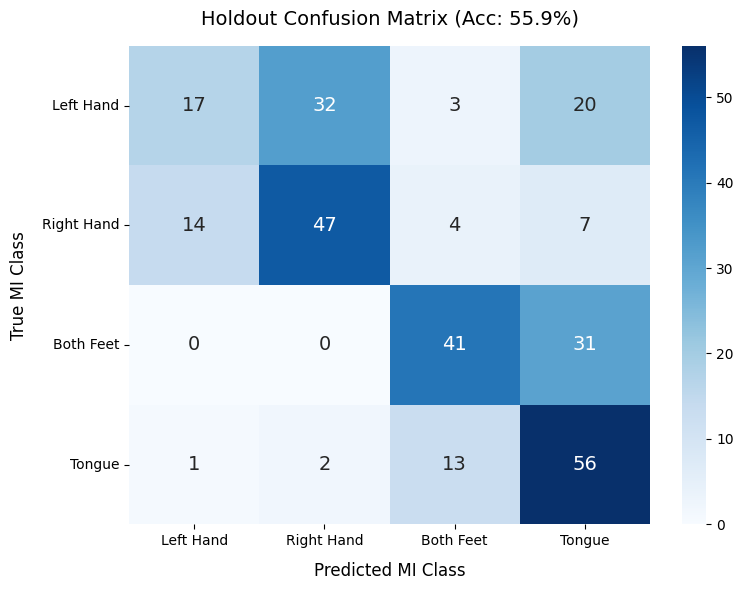

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5772 | Train Acc: 26.74%
Epoch [20/750] | CE Loss: 1.5282 | Train Acc: 24.65%
Epoch [30/750] | CE Loss: 1.4992 | Train Acc: 26.94%
Epoch [40/750] | CE Loss: 1.4823 | Train Acc: 24.51%
Epoch [50/750] | CE Loss: 1.4835 | Train Acc: 24.31%
Epoch [60/750] | CE Loss: 1.4518 | Train Acc: 26.18%
Epoch [70/750] | CE Loss: 1.4397 | Train Acc: 25.49%
Epoch [80/750] | CE Loss: 1.4341 | Train Acc: 24.58%
Epoch [90/750] | CE Loss: 1.4149 | Train Acc: 26.39%
Epoch [100/750] | CE Loss: 1.4120 | Train Acc: 26.11%
Epoch [110/750] | CE Loss: 1.4077 | Train Acc: 25.07%
Epoch [120/750] | CE Loss: 1.4094 | Train Acc: 25.21%
Epoch [130/750] | CE Loss: 1.4151 | Train Acc: 24.72%
Epoch [140/750] | CE Loss: 1.3994 | Train Acc: 25.90%
Epoch [150/750] | CE Loss: 1.4030 | Train Acc: 24.17%
Epoch [160/750] | CE Loss: 1.3922 | Train Acc: 25.21%
Epoch [170/750] | CE Loss: 1.3944 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  54.17%



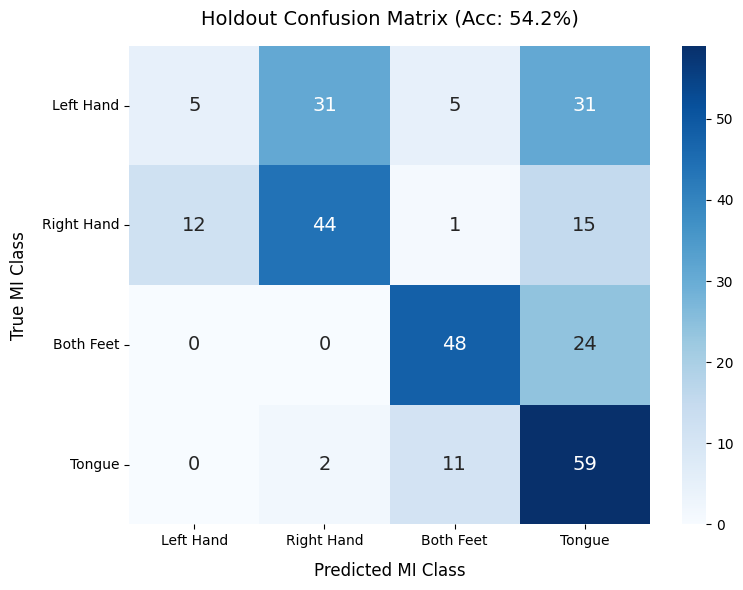

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6285 | Train Acc: 24.24%
Epoch [20/750] | CE Loss: 1.5800 | Train Acc: 24.44%
Epoch [30/750] | CE Loss: 1.5180 | Train Acc: 27.01%
Epoch [40/750] | CE Loss: 1.4998 | Train Acc: 26.32%
Epoch [50/750] | CE Loss: 1.4814 | Train Acc: 25.07%
Epoch [60/750] | CE Loss: 1.4672 | Train Acc: 26.18%
Epoch [70/750] | CE Loss: 1.4490 | Train Acc: 23.89%
Epoch [80/750] | CE Loss: 1.4230 | Train Acc: 25.49%
Epoch [90/750] | CE Loss: 1.4301 | Train Acc: 24.93%
Epoch [100/750] | CE Loss: 1.4083 | Train Acc: 27.78%
Epoch [110/750] | CE Loss: 1.4201 | Train Acc: 25.97%
Epoch [120/750] | CE Loss: 1.4084 | Train Acc: 25.28%
Epoch [130/750] | CE Loss: 1.3998 | Train Acc: 28.40%
Epoch [140/750] | CE Loss: 1.4025 | Train Acc: 26.18%
Epoch [150/750] | CE Loss: 1.3832 | Train Acc: 29.10%
Epoch [160/750] | CE Loss: 1.3907 | Train Acc: 28.19%
Epoch [170/750] | CE Loss: 1.3736 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  47.22%



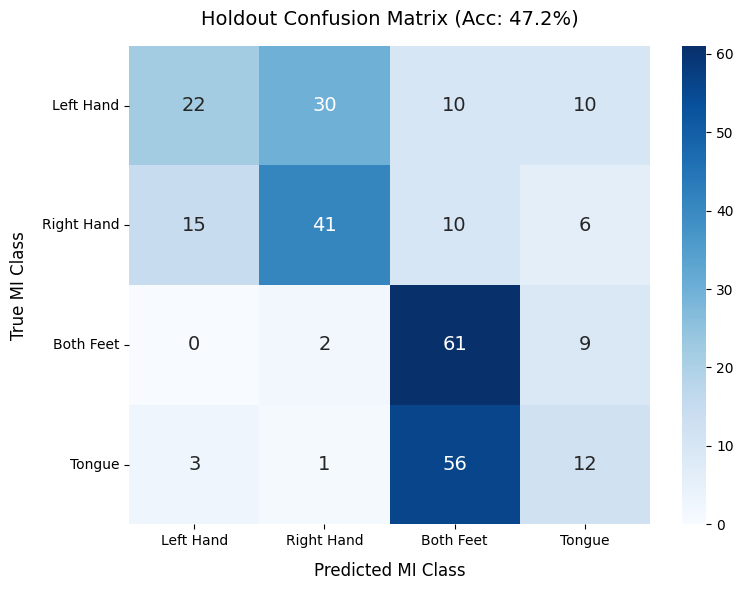

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6117 | Train Acc: 24.24%
Epoch [20/750] | CE Loss: 1.5393 | Train Acc: 25.07%
Epoch [30/750] | CE Loss: 1.5385 | Train Acc: 23.47%
Epoch [40/750] | CE Loss: 1.5160 | Train Acc: 25.76%
Epoch [50/750] | CE Loss: 1.4897 | Train Acc: 25.14%
Epoch [60/750] | CE Loss: 1.4647 | Train Acc: 26.25%
Epoch [70/750] | CE Loss: 1.4679 | Train Acc: 23.06%
Epoch [80/750] | CE Loss: 1.4500 | Train Acc: 24.86%
Epoch [90/750] | CE Loss: 1.4432 | Train Acc: 25.56%
Epoch [100/750] | CE Loss: 1.4278 | Train Acc: 25.76%
Epoch [110/750] | CE Loss: 1.4310 | Train Acc: 25.69%
Epoch [120/750] | CE Loss: 1.4203 | Train Acc: 26.39%
Epoch [130/750] | CE Loss: 1.4238 | Train Acc: 25.21%
Epoch [140/750] | CE Loss: 1.4216 | Train Acc: 26.11%
Epoch [150/750] | CE Loss: 1.4051 | Train Acc: 26.18%
Epoch [160/750] | CE Loss: 1.4046 | Train Acc: 26.88%
Epoch [170/750] | CE Loss: 1.4008 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  50.69%



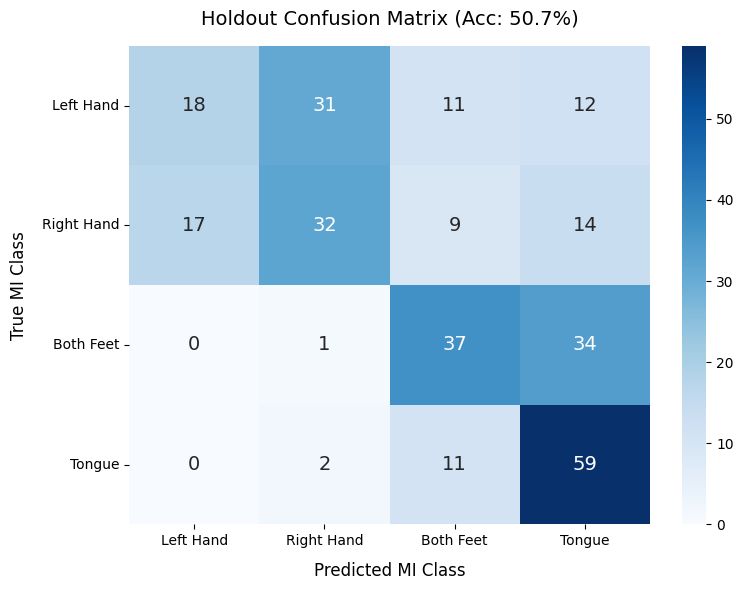

End of 5


In [15]:
lists.append(_run_(7, TCNet, parameters, batch_size, epochs, device, preprocessor))

## Subject 8


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5111 | Train Acc: 24.58%
Epoch [20/750] | CE Loss: 1.5182 | Train Acc: 25.69%
Epoch [30/750] | CE Loss: 1.5078 | Train Acc: 23.54%
Epoch [40/750] | CE Loss: 1.4663 | Train Acc: 27.50%
Epoch [50/750] | CE Loss: 1.4588 | Train Acc: 25.07%
Epoch [60/750] | CE Loss: 1.4417 | Train Acc: 23.68%
Epoch [70/750] | CE Loss: 1.4200 | Train Acc: 27.50%
Epoch [80/750] | CE Loss: 1.4129 | Train Acc: 26.74%
Epoch [90/750] | CE Loss: 1.4006 | Train Acc: 27.71%
Epoch [100/750] | CE Loss: 1.4083 | Train Acc: 27.43%
Epoch [110/750] | CE Loss: 1.4067 | Train Acc: 27.29%
Epoch [120/750] | CE Loss: 1.3822 | Train Acc: 28.12%
Epoch [130/750] | CE Loss: 1.3831 | Train Acc: 29.31%
Epoch [140/750] | CE Loss: 1.3688 | Train Acc: 31.04%
Epoch [150/750] | CE Loss: 1.3659 | Train Acc: 31.81%
Epoch [160/750] | CE Loss: 1.3614 | Train Acc: 33.26%
Epoch [170/750] | CE Loss: 1.3571 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  71.18%



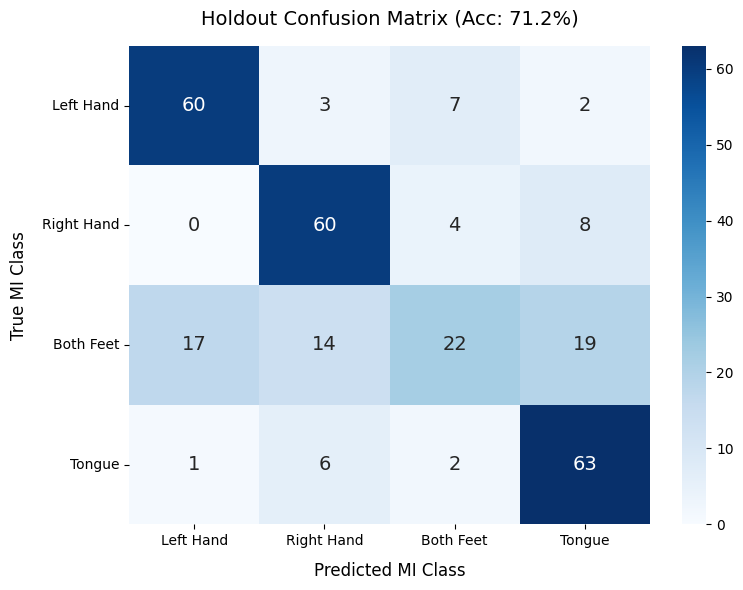

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5645 | Train Acc: 25.07%
Epoch [20/750] | CE Loss: 1.5511 | Train Acc: 26.18%
Epoch [30/750] | CE Loss: 1.5007 | Train Acc: 24.79%
Epoch [40/750] | CE Loss: 1.4578 | Train Acc: 26.74%
Epoch [50/750] | CE Loss: 1.4551 | Train Acc: 25.90%
Epoch [60/750] | CE Loss: 1.4502 | Train Acc: 27.15%
Epoch [70/750] | CE Loss: 1.4157 | Train Acc: 28.47%
Epoch [80/750] | CE Loss: 1.4163 | Train Acc: 26.53%
Epoch [90/750] | CE Loss: 1.4069 | Train Acc: 27.71%
Epoch [100/750] | CE Loss: 1.3931 | Train Acc: 28.61%
Epoch [110/750] | CE Loss: 1.4061 | Train Acc: 26.88%
Epoch [120/750] | CE Loss: 1.3856 | Train Acc: 30.21%
Epoch [130/750] | CE Loss: 1.3569 | Train Acc: 32.71%
Epoch [140/750] | CE Loss: 1.3328 | Train Acc: 35.97%
Epoch [150/750] | CE Loss: 1.3215 | Train Acc: 35.35%
Epoch [160/750] | CE Loss: 1.3249 | Train Acc: 34.17%
Epoch [170/750] | CE Loss: 1.2981 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  72.22%



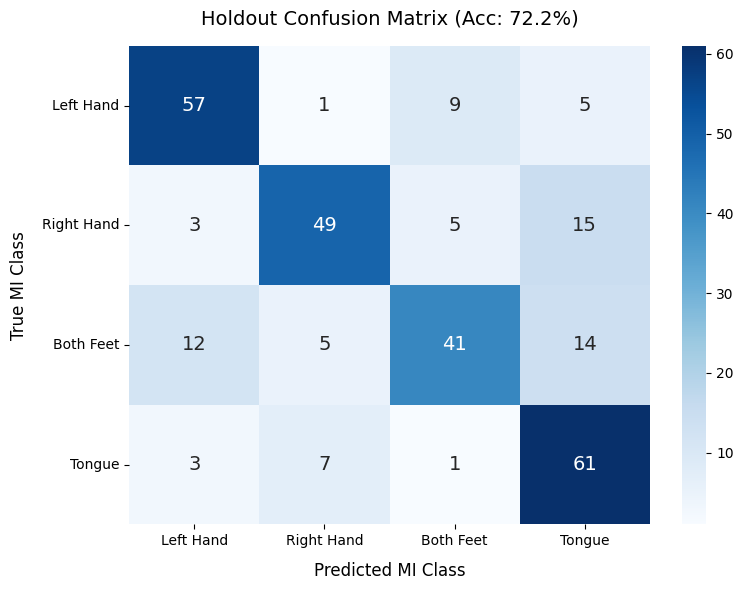

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6000 | Train Acc: 24.79%
Epoch [20/750] | CE Loss: 1.5133 | Train Acc: 26.74%
Epoch [30/750] | CE Loss: 1.4998 | Train Acc: 25.56%
Epoch [40/750] | CE Loss: 1.4838 | Train Acc: 25.00%
Epoch [50/750] | CE Loss: 1.4455 | Train Acc: 28.75%
Epoch [60/750] | CE Loss: 1.4291 | Train Acc: 28.82%
Epoch [70/750] | CE Loss: 1.4152 | Train Acc: 27.15%
Epoch [80/750] | CE Loss: 1.4105 | Train Acc: 28.26%
Epoch [90/750] | CE Loss: 1.3747 | Train Acc: 30.42%
Epoch [100/750] | CE Loss: 1.4014 | Train Acc: 28.54%
Epoch [110/750] | CE Loss: 1.3673 | Train Acc: 32.99%
Epoch [120/750] | CE Loss: 1.3601 | Train Acc: 34.86%
Epoch [130/750] | CE Loss: 1.3377 | Train Acc: 35.90%
Epoch [140/750] | CE Loss: 1.3200 | Train Acc: 37.15%
Epoch [150/750] | CE Loss: 1.3154 | Train Acc: 38.06%
Epoch [160/750] | CE Loss: 1.2943 | Train Acc: 39.24%
Epoch [170/750] | CE Loss: 1.2952 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  75.69%



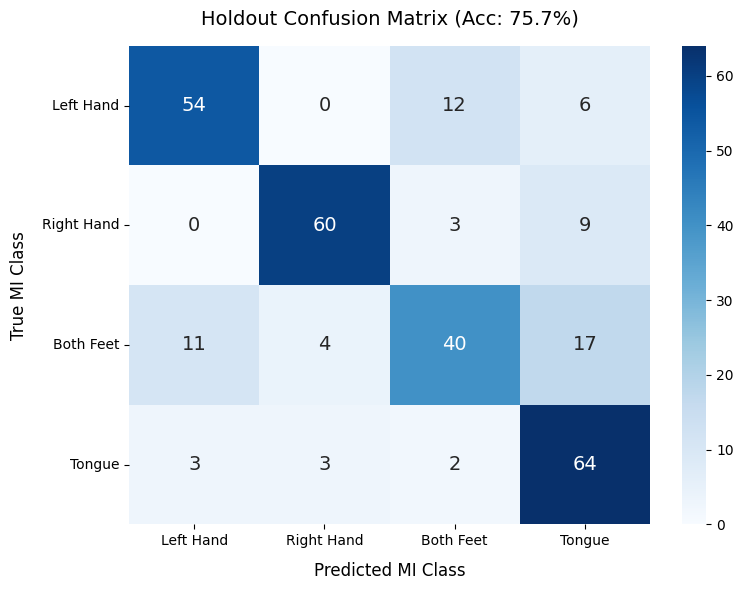

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5696 | Train Acc: 24.58%
Epoch [20/750] | CE Loss: 1.5246 | Train Acc: 24.79%
Epoch [30/750] | CE Loss: 1.5164 | Train Acc: 25.00%
Epoch [40/750] | CE Loss: 1.4709 | Train Acc: 25.49%
Epoch [50/750] | CE Loss: 1.4636 | Train Acc: 25.62%
Epoch [60/750] | CE Loss: 1.4463 | Train Acc: 27.64%
Epoch [70/750] | CE Loss: 1.4422 | Train Acc: 25.83%
Epoch [80/750] | CE Loss: 1.4300 | Train Acc: 28.47%
Epoch [90/750] | CE Loss: 1.4156 | Train Acc: 28.12%
Epoch [100/750] | CE Loss: 1.4020 | Train Acc: 28.54%
Epoch [110/750] | CE Loss: 1.3836 | Train Acc: 29.79%
Epoch [120/750] | CE Loss: 1.3734 | Train Acc: 30.28%
Epoch [130/750] | CE Loss: 1.3330 | Train Acc: 35.56%
Epoch [140/750] | CE Loss: 1.3131 | Train Acc: 36.25%
Epoch [150/750] | CE Loss: 1.2705 | Train Acc: 40.21%
Epoch [160/750] | CE Loss: 1.2640 | Train Acc: 39.72%
Epoch [170/750] | CE Loss: 1.2594 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  73.26%



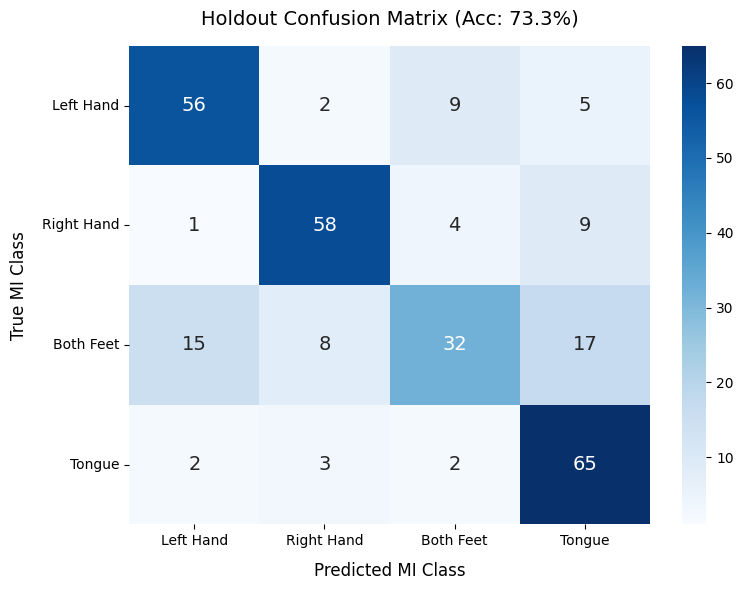

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6020 | Train Acc: 24.93%
Epoch [20/750] | CE Loss: 1.5828 | Train Acc: 26.18%
Epoch [30/750] | CE Loss: 1.5603 | Train Acc: 24.65%
Epoch [40/750] | CE Loss: 1.5209 | Train Acc: 26.32%
Epoch [50/750] | CE Loss: 1.4708 | Train Acc: 26.74%
Epoch [60/750] | CE Loss: 1.4560 | Train Acc: 26.04%
Epoch [70/750] | CE Loss: 1.4262 | Train Acc: 28.47%
Epoch [80/750] | CE Loss: 1.4214 | Train Acc: 29.93%
Epoch [90/750] | CE Loss: 1.4018 | Train Acc: 30.49%
Epoch [100/750] | CE Loss: 1.3899 | Train Acc: 31.39%
Epoch [110/750] | CE Loss: 1.3628 | Train Acc: 33.75%
Epoch [120/750] | CE Loss: 1.3434 | Train Acc: 36.60%
Epoch [130/750] | CE Loss: 1.3091 | Train Acc: 37.78%
Epoch [140/750] | CE Loss: 1.2977 | Train Acc: 38.06%
Epoch [150/750] | CE Loss: 1.2998 | Train Acc: 39.24%
Epoch [160/750] | CE Loss: 1.2524 | Train Acc: 42.08%
Epoch [170/750] | CE Loss: 1.2581 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  73.61%



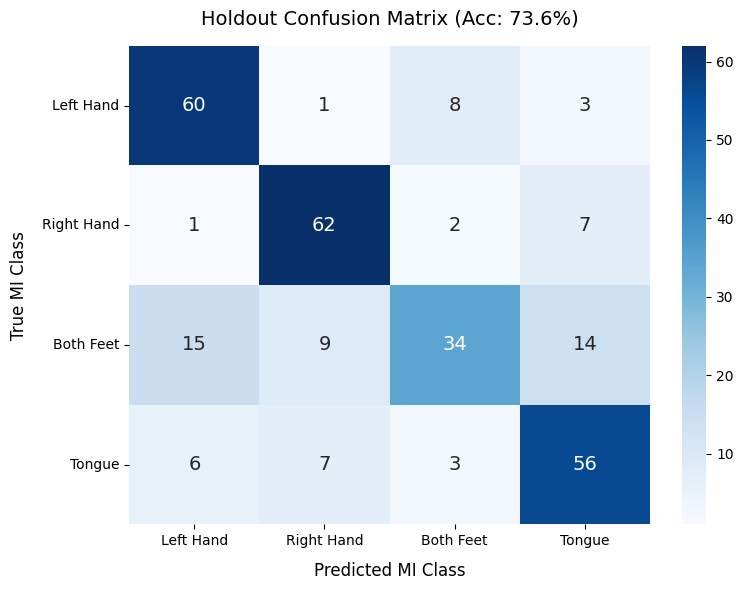

End of 5


In [16]:
lists.append(_run_(8, TCNet, parameters, batch_size, epochs, device, preprocessor))

## Subject 9


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5753 | Train Acc: 23.75%
Epoch [20/750] | CE Loss: 1.5411 | Train Acc: 24.86%
Epoch [30/750] | CE Loss: 1.5066 | Train Acc: 27.99%
Epoch [40/750] | CE Loss: 1.4946 | Train Acc: 26.11%
Epoch [50/750] | CE Loss: 1.4778 | Train Acc: 27.01%
Epoch [60/750] | CE Loss: 1.4839 | Train Acc: 24.93%
Epoch [70/750] | CE Loss: 1.4279 | Train Acc: 26.88%
Epoch [80/750] | CE Loss: 1.4327 | Train Acc: 27.64%
Epoch [90/750] | CE Loss: 1.4182 | Train Acc: 29.65%
Epoch [100/750] | CE Loss: 1.4163 | Train Acc: 29.58%
Epoch [110/750] | CE Loss: 1.3884 | Train Acc: 29.93%
Epoch [120/750] | CE Loss: 1.3733 | Train Acc: 31.39%
Epoch [130/750] | CE Loss: 1.3630 | Train Acc: 33.89%
Epoch [140/750] | CE Loss: 1.3201 | Train Acc: 37.43%
Epoch [150/750] | CE Loss: 1.3137 | Train Acc: 38.19%
Epoch [160/750] | CE Loss: 1.2989 | Train Acc: 37.36%
Epoch [170/750] | CE Loss: 1.3023 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  68.75%



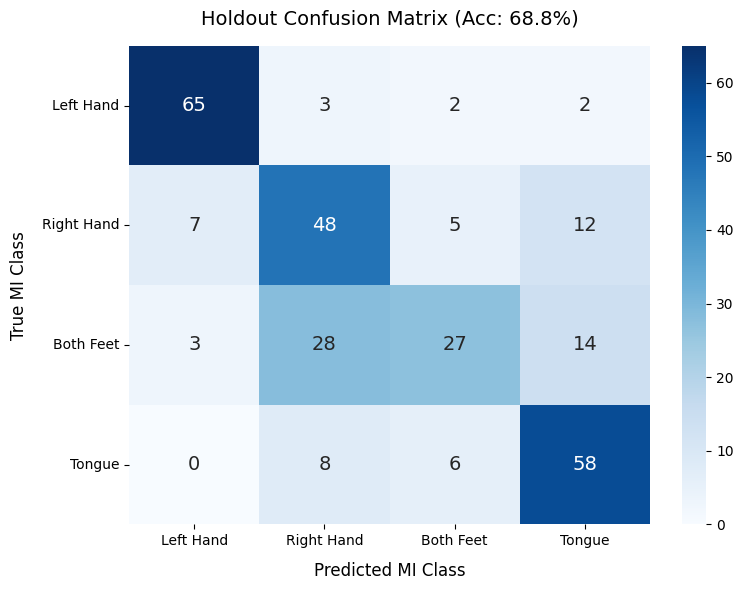

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.5939 | Train Acc: 23.89%
Epoch [20/750] | CE Loss: 1.5666 | Train Acc: 24.65%
Epoch [30/750] | CE Loss: 1.5017 | Train Acc: 27.22%
Epoch [40/750] | CE Loss: 1.5069 | Train Acc: 24.31%
Epoch [50/750] | CE Loss: 1.4711 | Train Acc: 25.62%
Epoch [60/750] | CE Loss: 1.4735 | Train Acc: 23.89%
Epoch [70/750] | CE Loss: 1.4454 | Train Acc: 26.18%
Epoch [80/750] | CE Loss: 1.4197 | Train Acc: 26.67%
Epoch [90/750] | CE Loss: 1.4038 | Train Acc: 26.46%
Epoch [100/750] | CE Loss: 1.4103 | Train Acc: 27.71%
Epoch [110/750] | CE Loss: 1.3922 | Train Acc: 28.68%
Epoch [120/750] | CE Loss: 1.3849 | Train Acc: 28.47%
Epoch [130/750] | CE Loss: 1.3753 | Train Acc: 31.39%
Epoch [140/750] | CE Loss: 1.3570 | Train Acc: 31.74%
Epoch [150/750] | CE Loss: 1.3396 | Train Acc: 34.72%
Epoch [160/750] | CE Loss: 1.3240 | Train Acc: 34.93%
Epoch [170/750] | CE Loss: 1.3218 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  53.47%



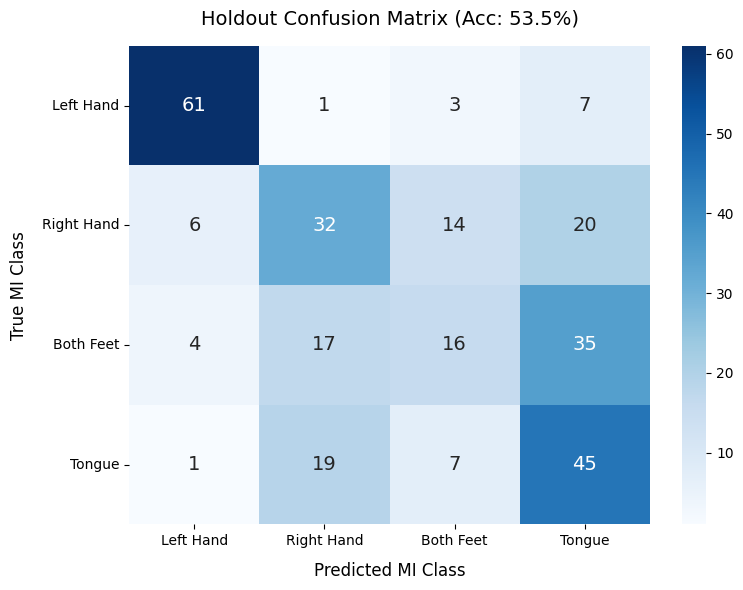

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6276 | Train Acc: 25.42%
Epoch [20/750] | CE Loss: 1.5758 | Train Acc: 26.53%
Epoch [30/750] | CE Loss: 1.5526 | Train Acc: 24.65%
Epoch [40/750] | CE Loss: 1.5390 | Train Acc: 25.69%
Epoch [50/750] | CE Loss: 1.5087 | Train Acc: 25.76%
Epoch [60/750] | CE Loss: 1.5016 | Train Acc: 25.76%
Epoch [70/750] | CE Loss: 1.4537 | Train Acc: 26.60%
Epoch [80/750] | CE Loss: 1.4422 | Train Acc: 27.92%
Epoch [90/750] | CE Loss: 1.4223 | Train Acc: 29.10%
Epoch [100/750] | CE Loss: 1.4338 | Train Acc: 27.15%
Epoch [110/750] | CE Loss: 1.4199 | Train Acc: 27.85%
Epoch [120/750] | CE Loss: 1.4227 | Train Acc: 27.43%
Epoch [130/750] | CE Loss: 1.4158 | Train Acc: 28.96%
Epoch [140/750] | CE Loss: 1.3934 | Train Acc: 29.03%
Epoch [150/750] | CE Loss: 1.3811 | Train Acc: 31.81%
Epoch [160/750] | CE Loss: 1.3601 | Train Acc: 33.33%
Epoch [170/750] | CE Loss: 1.3742 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  62.50%



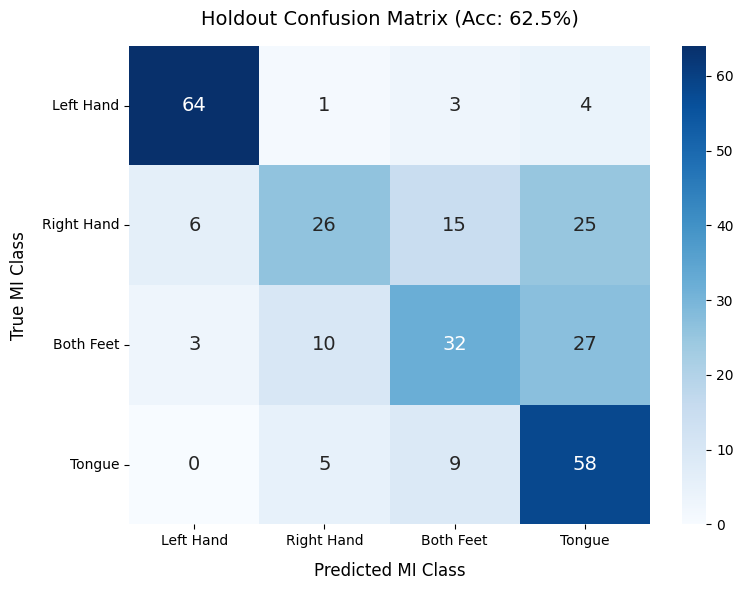

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6896 | Train Acc: 23.89%
Epoch [20/750] | CE Loss: 1.6136 | Train Acc: 23.54%
Epoch [30/750] | CE Loss: 1.5389 | Train Acc: 29.24%
Epoch [40/750] | CE Loss: 1.5248 | Train Acc: 27.22%
Epoch [50/750] | CE Loss: 1.5231 | Train Acc: 26.39%
Epoch [60/750] | CE Loss: 1.5118 | Train Acc: 24.31%
Epoch [70/750] | CE Loss: 1.4680 | Train Acc: 27.08%
Epoch [80/750] | CE Loss: 1.4652 | Train Acc: 26.88%
Epoch [90/750] | CE Loss: 1.4433 | Train Acc: 29.24%
Epoch [100/750] | CE Loss: 1.4295 | Train Acc: 29.65%
Epoch [110/750] | CE Loss: 1.4008 | Train Acc: 31.18%
Epoch [120/750] | CE Loss: 1.3933 | Train Acc: 29.93%
Epoch [130/750] | CE Loss: 1.3947 | Train Acc: 30.35%
Epoch [140/750] | CE Loss: 1.3502 | Train Acc: 33.61%
Epoch [150/750] | CE Loss: 1.3397 | Train Acc: 35.35%
Epoch [160/750] | CE Loss: 1.3325 | Train Acc: 37.29%
Epoch [170/750] | CE Loss: 1.3257 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  61.11%



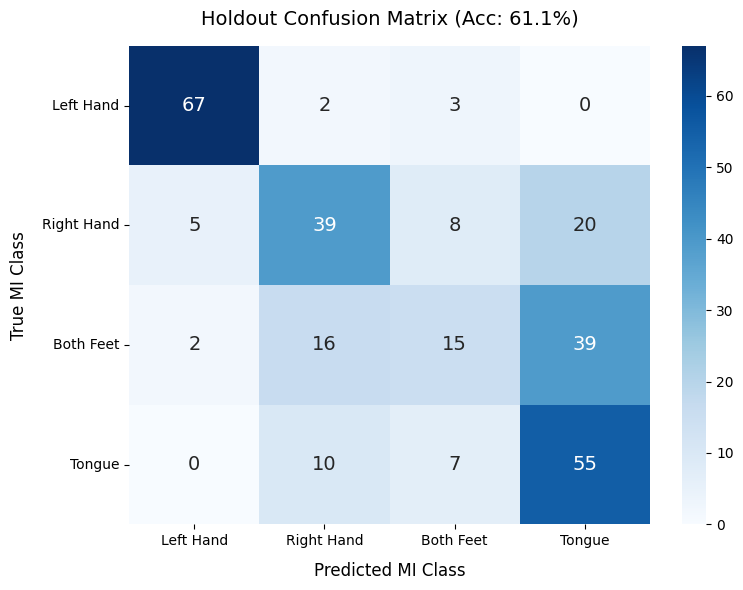

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/750] | CE Loss: 1.6547 | Train Acc: 25.14%
Epoch [20/750] | CE Loss: 1.5822 | Train Acc: 27.29%
Epoch [30/750] | CE Loss: 1.5601 | Train Acc: 25.97%
Epoch [40/750] | CE Loss: 1.5366 | Train Acc: 25.76%
Epoch [50/750] | CE Loss: 1.5031 | Train Acc: 28.12%
Epoch [60/750] | CE Loss: 1.4846 | Train Acc: 28.26%
Epoch [70/750] | CE Loss: 1.4704 | Train Acc: 25.35%
Epoch [80/750] | CE Loss: 1.4745 | Train Acc: 24.31%
Epoch [90/750] | CE Loss: 1.4419 | Train Acc: 27.22%
Epoch [100/750] | CE Loss: 1.4297 | Train Acc: 27.85%
Epoch [110/750] | CE Loss: 1.4212 | Train Acc: 27.08%
Epoch [120/750] | CE Loss: 1.4001 | Train Acc: 29.31%
Epoch [130/750] | CE Loss: 1.4171 | Train Acc: 26.39%
Epoch [140/750] | CE Loss: 1.3909 | Train Acc: 30.21%
Epoch [150/750] | CE Loss: 1.3863 | Train Acc: 31.11%
Epoch [160/750] | CE Loss: 1.3721 | Train Acc: 32.08%
Epoch [170/750] | CE Loss: 1.3469 | Tra

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  57.99%



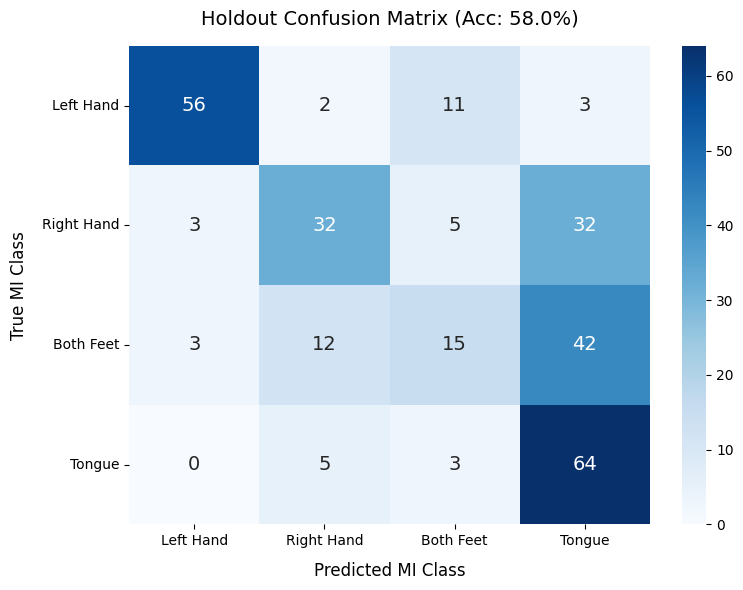

End of 5


In [17]:
lists.append(_run_(9, TCNet, parameters, batch_size, epochs, device, preprocessor))

# Results

In [18]:
print(lists)

[[70.13888888888889, 68.75, 64.58333333333333, 63.19444444444444, 57.291666666666664], [36.111111111111114, 41.666666666666664, 38.19444444444444, 35.763888888888886, 44.44444444444444], [73.26388888888889, 73.26388888888889, 75.69444444444444, 72.91666666666667, 72.22222222222223], [36.80555555555556, 45.486111111111114, 41.31944444444444, 37.15277777777778, 41.666666666666664], [31.944444444444443, 31.59722222222222, 34.72222222222222, 28.47222222222222, 42.013888888888886], [34.02777777777778, 32.986111111111114, 31.944444444444443, 29.166666666666668, 29.51388888888889], [55.55555555555556, 55.90277777777778, 54.166666666666664, 47.22222222222222, 50.69444444444444], [71.18055555555556, 72.22222222222223, 75.69444444444444, 73.26388888888889, 73.61111111111111], [68.75, 53.47222222222222, 62.5, 61.111111111111114, 57.986111111111114]]


In [19]:
maxes = [max(row) for row in lists]
print(maxes)

[70.13888888888889, 44.44444444444444, 75.69444444444444, 45.486111111111114, 42.013888888888886, 34.02777777777778, 55.90277777777778, 75.69444444444444, 68.75]


In [20]:
np.mean(maxes) 

np.float64(56.90586419753087)

In [21]:
model = TCNet(*parameters)
summary(model)

Layer (type:depth-idx)                        Param #
TCNet                                         --
├─EEGTCNet: 1-1                               --
│    └─Rearrange: 2-1                         --
│    └─_EEGNetTC: 2-2                         --
│    │    └─ELU: 3-1                          --
│    │    └─Conv2d: 3-2                       256
│    │    └─BatchNorm2d: 3-3                  16
│    │    └─Conv2d: 3-4                       704
│    │    └─BatchNorm2d: 3-5                  64
│    │    └─AvgPool2d: 3-6                    --
│    │    └─Dropout: 3-7                      --
│    │    └─Conv2d: 3-8                       1,024
│    │    └─Conv2d: 3-9                       1,024
│    │    └─BatchNorm2d: 3-10                 64
│    │    └─AvgPool2d: 3-11                   --
│    │    └─Dropout: 3-12                     --
│    └─Rearrange: 2-3                         --
│    └─_TCNBlock: 2-4                         --
│    │    └─ELU: 3-13                         --
│    │ 